# Tarification automobile — Modèle de fréquence (parties 1 à 4)
## Analyse exploratoire, préparation des données et régression logistique

**Objectif du projet** : estimer la prime pure $\mathbb{E}[S] = \mathbb{P}(S>0) \times \mathbb{E}[S \mid S>0]$.

Ce notebook couvre :
- **Partie 1 (rappel)** : rôle de chaque fichier ;
- **Partie 2** : analyse exploratoire — cibles, variables explicatives, anomalies, fuites de données, lien avec la cible ;
- **Partie 3** : préparation — découpage train / validation, nettoyage, classement des variables, encodage ;
- **Partie 4** : modélisation de la fréquence par régression logistique, puis export des probabilités sur le test.

La gravité est dans le notebook 02, la prime finale et la soumission Kaggle dans le notebook 03.

> Périmètre : nous nous concentrons sur le **modèle de fréquence** (probabilité d'avoir au moins un sinistre). La cible de gravité est seulement décrite brièvement (§2.2) ; elle est modélisée dans le notebook 02.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

SEED = 42  # graine unique pour rendre tous les tirages aléatoires reproductibles
CIBLE = "nombre_sinistres"
MONTANT = "montant_sinistre"

---
# Partie 1 — Prise en main des données

| Fichier | Rôle |
|---|---|
| `Data/train.csv` | Données d'entraînement : variables explicatives **et** cibles (`nombre_sinistres`, `montant_sinistre`) |
| `Data/test.csv` | Données de test Kaggle : variables explicatives seulement, il faut prédire la prime |

`code_postal` est lu comme du texte pour ne pas perdre les zéros initiaux (ex. `01000`).

**Attention au nom** : malgré son nom, `code_postal` contient en fait un **code commune INSEE**. On y trouve par exemple des codes commençant par `2A` ou `2B` (Corse), ce qui n'existe pas dans les codes postaux. Les deux premiers caractères donnent bien le **département**, ce que nous utilisons plus loin.

In [2]:
# Racine du projet : le dossier qui contient Data/ (le notebook peut être lancé depuis notebooks/ ou depuis la racine)
from pathlib import Path
RACINE = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "Data" / "train.csv").exists())

train = pd.read_csv(RACINE / "Data" / "train.csv", dtype={"code_postal": str})
test = pd.read_csv(RACINE / "Data" / "test.csv", dtype={"code_postal": str})

print("train :", train.shape)
print("test  :", test.shape)

colonnes_absentes_test = sorted(set(train.columns) - set(test.columns))
print("\nColonnes du train absentes du test :", colonnes_absentes_test)
print("Colonnes du test absentes du train :", sorted(set(test.columns) - set(train.columns)))
print("\nindex test : de", test["index"].min(), "à", test["index"].max())
train.head()

train : (50000, 33)
test  : (50000, 28)

Colonnes du train absentes du test : ['id_client', 'id_contrat', 'id_vehicule', 'montant_sinistre', 'nombre_sinistres']
Colonnes du test absentes du train : []

index test : de 50000 à 99999


,index,id_client,id_vehicule,id_contrat,bonus,type_contrat,duree_contrat,anciennete_info,freq_paiement,paiement,utilisation,code_postal,conducteur2,age_conducteur1,age_conducteur2,sex_conducteur1,sex_conducteur2,anciennete_permis1,anciennete_permis2,anciennete_vehicule,cylindre_vehicule,din_vehicule,essence_vehicule,marque_vehicule,modele_vehicule,debut_vente_vehicule,fin_vente_vehicule,vitesse_vehicule,type_vehicule,prix_vehicule,poids_vehicule,nombre_sinistres,montant_sinistre
0,0,A00000001,V01,A00000001-V01,0.5,Maxi,29,9,Biannual,No,Retired,36233,No,85,0,M,NaN,62,0,10.0,1587,98,Gasoline,PEUGEOT,306,10,9,182,Tourism,20700,1210,0,0.0
1,1,A00000002,V01,A00000002-V01,0.5,Maxi,3,1,Biannual,No,Retired,92073,No,69,0,M,NaN,39,0,4.0,2149,170,Diesel,MERCEDES BENZ,C220,4,2,229,Tourism,34250,1510,0,0.0
2,2,A00000003,V01,A00000003-V01,0.5,Maxi,2,2,Yearly,No,WorkPrivate,92026,No,37,0,M,NaN,18,0,11.0,1991,150,Gasoline,BMW,Z3,12,11,210,Tourism,28661,1270,0,0.0
3,3,A00000004,V01,A00000004-V01,0.5,Median2,22,1,Yearly,No,WorkPrivate,78537,Yes,81,21,M,F,54,3,16.0,1781,90,Gasoline,VOLKSWAGEN,GOLF,18,15,180,Tourism,14407,1020,0,0.0
4,4,A00000005,V01,A00000005-V01,0.5,Maxi,16,4,Biannual,No,Retired,38544,Yes,62,68,F,M,37,48,11.0,1598,108,Gasoline,RENAULT,LAGUNA,13,11,195,Tourism,16770,1230,0,0.0


**Constat** : le test contient toutes les variables du train **sauf** les deux cibles et les trois identifiants (`id_client`, `id_vehicule`, `id_contrat`).
Toute variable présente dans le test est donc connue au moment de la tarification ; c'est un premier indice pour la question des fuites (§2.4).

---
# Partie 2 — Analyse exploratoire

## 2.1 Cible de fréquence : `nombre_sinistres`

,Effectif,Pourcentage (%)
nombre_sinistres,,
0,47083,94.17
1,2917,5.83


Taux de sinistralité moyen : 5.83%


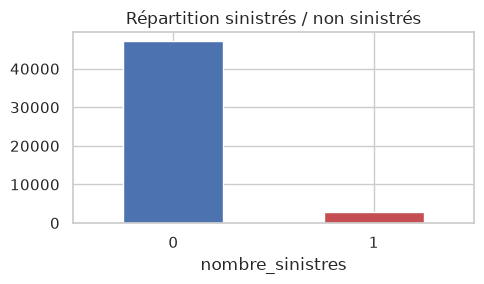

In [3]:
repartition = pd.DataFrame({
    "Effectif": train[CIBLE].value_counts(),
    "Pourcentage (%)": train[CIBLE].value_counts(normalize=True).mul(100).round(2),
}).sort_index()
display(repartition)

taux_moyen = train[CIBLE].mean()
print(f"Taux de sinistralité moyen : {taux_moyen:.2%}")

ax = repartition["Effectif"].plot.bar(figsize=(5, 3), color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Répartition sinistrés / non sinistrés")
ax.set_xlabel("nombre_sinistres")
plt.tight_layout()
plt.show()

**Constats**
- `nombre_sinistres` ne prend que les valeurs 0 et 1 : la cible est directement **binaire**.
- Les classes sont **très déséquilibrées** : environ 94 % de non-sinistrés pour 6 % de sinistrés.

**Conséquence**
- Pour le découpage, il faudra **stratifier** sur la cible afin de garder environ 6 % de sinistrés dans chaque jeu.

> Les conséquences de ce déséquilibre sur le choix de la métrique sont traitées en **partie 4**, avec la modélisation.

## 2.2 Cible de gravité : `montant_sinistre` (description rapide)

Le montant n'est pas la cible de ce notebook, mais on vérifie deux choses utiles pour la suite :
- le montant est nul **si et seulement si** il n'y a pas de sinistre (c'est ce qui en fait une fuite directe pour la fréquence, voir 2.4) ;
- l'allure de sa distribution chez les sinistrés.

In [4]:
# Le montant est-il nul exactement quand il n'y a pas de sinistre ?
sinistres = train[train[CIBLE] == 1]
print("Montant nul pour tous les non-sinistrés :", (train.loc[train[CIBLE] == 0, MONTANT] == 0).all())
print("Montant positif pour tous les sinistrés :", (sinistres[MONTANT] > 0).all())

# Distribution du montant chez les sinistrés seulement
sinistres[MONTANT].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame("montant (€)")

Montant nul pour tous les non-sinistrés : True
Montant positif pour tous les sinistrés : True


,montant (€)
count,2917.0
mean,1772.0
std,1464.0
min,601.0
50%,1236.0
90%,3337.0
99%,6963.0
max,21827.0


**Constats**
- Le montant est nul pour **tous** les non-sinistrés et positif pour **tous** les sinistrés : `montant_sinistre > 0` équivaut exactement à `nombre_sinistres = 1`. C'est pourquoi le montant est une fuite directe pour le modèle de fréquence (exclu, voir 2.4).
- Chez les 2 917 sinistrés, le montant est très **asymétrique** : médiane 1 236 €, moyenne 1 772 €, 99ᵉ centile 6 963 €, maximum 21 827 €. Cette asymétrie concerne le modèle de gravité, traité dans l'autre notebook.

## 2.3 Description des variables explicatives

On regroupe les colonnes par thème métier pour structurer l'analyse.

In [5]:
IDENTIFIANTS = ["index", "id_client", "id_vehicule", "id_contrat"]
CIBLES = [CIBLE, MONTANT]

VAR_CONTRAT = ["bonus", "type_contrat", "duree_contrat", "anciennete_info",
               "freq_paiement", "paiement", "utilisation"]
VAR_CONDUCTEURS = ["conducteur2", "age_conducteur1", "age_conducteur2",
                   "sex_conducteur1", "sex_conducteur2",
                   "anciennete_permis1", "anciennete_permis2"]
VAR_VEHICULE = ["anciennete_vehicule", "cylindre_vehicule", "din_vehicule",
                "essence_vehicule", "marque_vehicule", "modele_vehicule",
                "debut_vente_vehicule", "fin_vente_vehicule", "vitesse_vehicule",
                "type_vehicule", "prix_vehicule", "poids_vehicule"]
VAR_GEO = ["code_postal"]

explicatives = VAR_CONTRAT + VAR_CONDUCTEURS + VAR_VEHICULE + VAR_GEO
assert set(explicatives + IDENTIFIANTS + CIBLES) == set(train.columns)

numeriques = [c for c in explicatives if pd.api.types.is_numeric_dtype(train[c])]
categorielles = [c for c in explicatives if c not in numeriques]
print("Numériques   :", numeriques)
print("Catégorielles:", categorielles)

Numériques   : ['bonus', 'duree_contrat', 'anciennete_info', 'age_conducteur1', 'age_conducteur2', 'anciennete_permis1', 'anciennete_permis2', 'anciennete_vehicule', 'cylindre_vehicule', 'din_vehicule', 'debut_vente_vehicule', 'fin_vente_vehicule', 'vitesse_vehicule', 'prix_vehicule', 'poids_vehicule']
Catégorielles: ['type_contrat', 'freq_paiement', 'paiement', 'utilisation', 'conducteur2', 'sex_conducteur1', 'sex_conducteur2', 'essence_vehicule', 'marque_vehicule', 'modele_vehicule', 'type_vehicule', 'code_postal']


In [6]:
# Tableau de synthèse : type, manquants, cardinalité, statistiques descriptives
resume = pd.DataFrame(index=explicatives)
resume["Thème"] = (["Contrat"] * len(VAR_CONTRAT) + ["Conducteurs"] * len(VAR_CONDUCTEURS)
                   + ["Véhicule"] * len(VAR_VEHICULE) + ["Géographie"])
resume["Type"] = ["numérique" if c in numeriques else "catégorielle" for c in explicatives]
resume["Manquants"] = train[explicatives].isna().sum()
resume["Manquants (%)"] = (train[explicatives].isna().mean() * 100).round(2)
resume["Modalités"] = train[explicatives].nunique()

stats = train[numeriques].describe(percentiles=[0.01, 0.5, 0.99]).T
stats = stats[["mean", "std", "min", "1%", "50%", "99%", "max"]]
stats.columns = ["Moyenne", "Écart-type", "Min", "P1", "Médiane", "P99", "Max"]
resume.join(stats.round(2))

,Thème,Type,Manquants,Manquants (%),Modalités,Moyenne,Écart-type,Min,P1,Médiane,P99,Max
bonus,Contrat,numérique,0,0.00,73,0.54,0.10,0.5,0.5,0.5,0.95,2.16
type_contrat,Contrat,catégorielle,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duree_contrat,Contrat,numérique,0,0.00,41,11.09,8.57,1.0,1.0,9.0,31.00,41.00
anciennete_info,Contrat,numérique,0,0.00,25,2.73,2.35,1.0,1.0,2.0,12.00,25.00
freq_paiement,Contrat,catégorielle,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
paiement,Contrat,catégorielle,0,0.00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
utilisation,Contrat,catégorielle,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
conducteur2,Conducteurs,catégorielle,0,0.00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_conducteur1,Conducteurs,numérique,0,0.00,83,54.65,14.87,19.0,24.0,54.0,86.00,101.00
age_conducteur2,Conducteurs,numérique,0,0.00,81,15.57,23.99,0.0,0.0,0.0,78.00,99.00


### Variables catégorielles : modalités et modalités rares
Une modalité trop rare (ici, moins de 50 lignes) ne permet pas d'estimer un effet fiable : le modèle risque d'apprendre du bruit (sur-apprentissage).

In [7]:
SEUIL_RARE = 50

lignes = []
for c in categorielles:
    vc = train[c].value_counts()
    lignes.append({
        "variable": c,
        "modalités": vc.size,
        "modalités rares (< %d lignes)" % SEUIL_RARE: (vc < SEUIL_RARE).sum(),
        "lignes concernées": vc[vc < SEUIL_RARE].sum(),
        "modalité la plus fréquente": f"{vc.index[0]} ({vc.iloc[0] / len(train):.0%})",
    })
display(pd.DataFrame(lignes).set_index("variable"))

for c in ["type_contrat", "freq_paiement", "paiement", "utilisation",
          "essence_vehicule", "type_vehicule", "conducteur2", "sex_conducteur1"]:
    print(c, train[c].value_counts(dropna=False).to_dict())

,modalités,modalités rares (< 50 lignes),lignes concernées,modalité la plus fréquente
variable,,,,
type_contrat,4,0,0,Maxi (65%)
freq_paiement,4,0,0,Yearly (38%)
paiement,2,0,0,No (96%)
utilisation,4,1,48,WorkPrivate (66%)
conducteur2,2,0,0,No (67%)
sex_conducteur1,2,0,0,M (60%)
sex_conducteur2,2,0,0,F (20%)
essence_vehicule,3,1,46,Diesel (55%)
marque_vehicule,89,54,527,RENAULT (27%)


type_contrat {'Maxi': 32360, 'Median2': 8759, 'Median1': 4638, 'Mini': 4243}
freq_paiement {'Yearly': 18948, 'Monthly': 15045, 'Biannual': 14769, 'Quarterly': 1238}
paiement {'No': 47927, 'Yes': 2073}
utilisation {'WorkPrivate': 32941, 'Retired': 13344, 'Professional': 3667, 'AllTrips': 48}
essence_vehicule {'Diesel': 27476, 'Gasoline': 22478, 'Hybrid': 46}
type_vehicule {'Tourism': 45036, 'Commercial': 4964}
conducteur2 {'No': 33406, 'Yes': 16594}
sex_conducteur1 {'M': 30097, 'F': 19903}


**Constats**
- **Faible cardinalité (≤ 4 modalités)** : `type_contrat`, `freq_paiement`, `paiement`, `utilisation`, `essence_vehicule`, `type_vehicule`, `conducteur2`, `sex_*`. Quelques modalités rares : `utilisation = AllTrips` (48 lignes), `essence_vehicule = Hybrid` (46 lignes).
- **Forte cardinalité** :
  - `marque_vehicule` : 89 modalités, dont la majorité sont rares ;
  - `modele_vehicule` : 886 modalités, dont plus de 80 % sont rares ;
  - `code_postal` (en réalité un code commune INSEE) : environ 12 800 modalités, inutilisable tel quel.

  Ces variables demanderont un traitement spécifique : regroupement des rares, encodage par la cible, ou réduction au **département** pour le code commune.
- `sex_conducteur2` a environ 67 % de « manquants » : on vérifie plus bas qu'ils correspondent exactement aux contrats sans second conducteur (manquant **structurel**).

In [8]:
# Code commune INSEE -> département (2 premiers caractères, 2A / 2B pour la Corse)
dept = train["code_postal"].str[:2]
print("Nombre de départements :", dept.nunique())
print("Départements du test absents du train :",
      set(test["code_postal"].str[:2]) - set(dept))
print("Modèles de véhicule du test absents du train :",
      len(set(test["modele_vehicule"]) - set(train["modele_vehicule"])))
print("Marques du test absentes du train :",
      len(set(test["marque_vehicule"]) - set(train["marque_vehicule"])))

Nombre de départements : 96
Départements du test absents du train : set()
Modèles de véhicule du test absents du train : 137


Marques du test absentes du train : 12


→ Des modèles (et éventuellement des marques) du test n'existent pas dans le train : la préparation devra **gérer les modalités inconnues** sans planter.

### Variables numériques : valeurs aberrantes et incohérences

In [9]:
def compter(masque_train, masque_test, description, traitement):
    return {"anomalie": description, "train": int(masque_train.sum()),
            "test": int(masque_test.sum()), "traitement prévu (partie 3)": traitement}

anomalies = pd.DataFrame([
    compter(train["poids_vehicule"] == 0, test["poids_vehicule"] == 0,
            "poids_vehicule = 0", "valeur impossible → NaN puis imputation"),
    compter(train["cylindre_vehicule"] == 0, test["cylindre_vehicule"] == 0,
            "cylindre_vehicule = 0", "valeur impossible → NaN puis imputation"),
    compter(train["anciennete_vehicule"].isna(), test["anciennete_vehicule"].isna(),
            "anciennete_vehicule manquante", "imputation par la médiane"),
    compter(train["fin_vente_vehicule"] > train["debut_vente_vehicule"],
            test["fin_vente_vehicule"] > test["debut_vente_vehicule"],
            "fin de vente plus ancienne que début de vente", "rien (aucun cas)"),
]).set_index("anomalie")
anomalies


,train,test,traitement prévu (partie 3)
anomalie,,,
poids_vehicule = 0,1883,1861,valeur impossible → NaN puis imputation
cylindre_vehicule = 0,3,2,valeur impossible → NaN puis imputation
anciennete_vehicule manquante,1,0,imputation par la médiane
fin de vente plus ancienne que début de vente,0,0,rien (aucun cas)


In [10]:
# Second conducteur : les zéros et les NaN sont-ils structurels ?
sans_c2 = train["conducteur2"] == "No"
print("Sans 2e conducteur :", sans_c2.sum())
print("  dont age_conducteur2 = 0        :", (train.loc[sans_c2, "age_conducteur2"] == 0).sum())
print("  dont anciennete_permis2 = 0     :", (train.loc[sans_c2, "anciennete_permis2"] == 0).sum())
print("  dont sex_conducteur2 manquant   :", train.loc[sans_c2, "sex_conducteur2"].isna().sum())
print("Avec 2e conducteur et age_conducteur2 = 0 :",
      ((~sans_c2) & (train["age_conducteur2"] == 0)).sum())

Sans 2e conducteur : 33406
  dont age_conducteur2 = 0        : 33406
  dont anciennete_permis2 = 0     : 33406
  dont sex_conducteur2 manquant   : 33406
Avec 2e conducteur et age_conducteur2 = 0 : 0


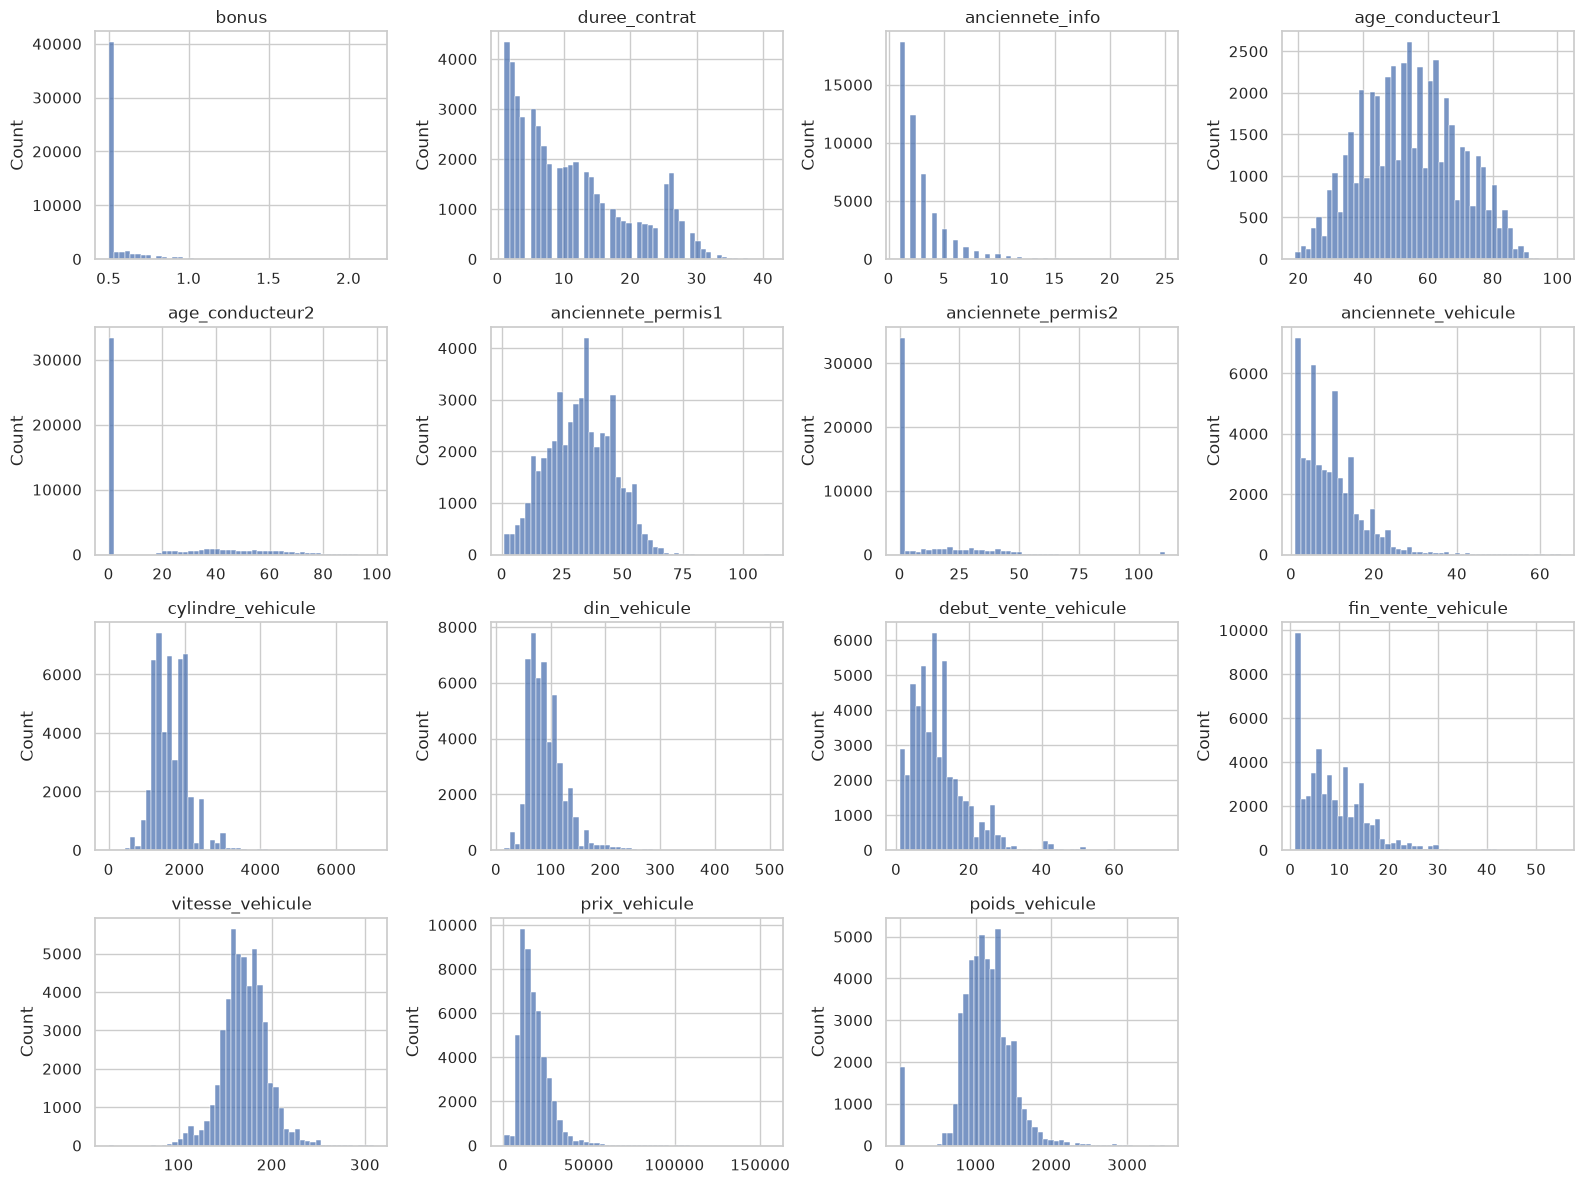

In [11]:
# Distributions des variables numériques (repérer queues lourdes et pics)
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, c in zip(axes.ravel(), numeriques):
    sns.histplot(train[c], bins=50, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")
for ax in axes.ravel()[len(numeriques):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Constats**
- `poids_vehicule = 0` concerne environ 1 900 lignes (aussi présentes dans le test) : ce n'est pas un vrai poids mais une **valeur manquante déguisée**. Même chose pour les 3 `cylindre_vehicule = 0`.
- Pour les contrats **sans second conducteur**, `age_conducteur2 = 0`, `anciennete_permis2 = 0` et `sex_conducteur2 = NaN` dans 100 % des cas. Ce ne sont pas des erreurs mais des **valeurs structurelles** : l'information est portée par `conducteur2`.
- Plusieurs variables ont une **queue lourde à droite** (`prix_vehicule` jusqu'à environ 155 000 €, `din_vehicule` jusqu'à 500 ch, `anciennete_vehicule`) : un passage au log aidera les modèles linéaires.
- `bonus` est concentré à 0,50 (bonus maximal), avec une longue traîne de malus jusqu'à 2,16.

## 2.4 Fuites de données

**Critère** : une variable est utilisable seulement si sa valeur est **connue au moment de la signature du contrat**, c'est-à-dire avant la période de couverture sur laquelle on compte les sinistres.

| Variable(s) | Connue à la tarification ? | Décision |
|---|---|---|
| `nombre_sinistres` | Non — c'est la cible | Cible |
| `montant_sinistre` | Non — observé après le sinistre, et `> 0` si et seulement si `nombre_sinistres = 1` | **Exclue** (fuite directe) |
| `id_client`, `id_vehicule`, `id_contrat`, `index` | Oui, mais sans signification métier et absents du test | **Exclues** des variables (`id_client` gardé pour le découpage) |
| `bonus` | Oui : le coefficient bonus-malus est calculé **à partir des sinistres passés**, fixé au début de la période | Conservée |
| `type_contrat`, `duree_contrat`, `anciennete_info`, `freq_paiement`, `paiement`, `utilisation` | Oui : caractéristiques du contrat choisies à la souscription | Conservées |
| Conducteurs, véhicule, code commune | Oui : déclarés à la souscription | Conservées (sauf sexe, voir 3.1) |

Ces variables de contrat sont d'ailleurs **toutes présentes dans `test.csv`**, ce qui confirme qu'elles sont disponibles au moment de prédire.

> Nuance : on suppose que `bonus` est la valeur au **début** de la période. S'il était mis à jour après les sinistres de la période, il contiendrait une fuite. Ici, sa faible relation avec la cible (§3.4) et sa présence dans le test rendent cette hypothèse raisonnable.

## 2.5 Lien entre les variables explicatives et la cible de fréquence

### Pourquoi ne pas se contenter d'une matrice de corrélation ?
La proportion de non-sinistrés étant de 94 % contre 6 %, les coefficients de corrélation sont mécaniquement très petits, **même quand le lien est fort**. De plus, la corrélation ne mesure que les liens **linéaires** et ne s'applique pas aux variables **catégorielles** (`type_contrat`, `utilisation`…).

### Méthode retenue : le taux de sinistralité par classe
Pour chaque variable, on calcule le **taux de sinistres** dans chaque modalité (variables catégorielles) ou dans chacune des **10 classes de même effectif** (déciles, variables numériques). On le compare au taux moyen du portefeuille (ligne rouge). Dix classes plutôt que cinq permettent de voir des effets non monotones (par exemple un excès de risque limité aux plus jeunes conducteurs).

C'est l'outil de référence en tarification : il est lisible, il capte les effets non linéaires, et il s'interprète directement en écart de risque.

Le **classement chiffré** de toutes les variables (Gini univarié) demande un jeu de validation : il est fait en **3.4**, après le découpage.

In [12]:
def taux_par_classe(df, col, cible=CIBLE, n_bins=10):
    # Taux de sinistres et effectif par modalité (ou par décile pour une variable continue :
    # 10 classes de même effectif, plus fin que 5 pour voir les effets en U)
    x = df[col]
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > 10:
        x = pd.qcut(x, n_bins, duplicates="drop")
    return df.groupby(x, observed=True)[cible].agg(taux="mean", effectif="size")


def tracer_taux(df, colonnes, n_cols=3, cible=CIBLE):
    n_rows = int(np.ceil(len(colonnes) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 3.6 * n_rows))
    taux_global = df[cible].mean()
    for ax, col in zip(np.ravel(axes), colonnes):
        g = taux_par_classe(df, col, cible)
        # intervalle de confiance à 95 % d'une proportion : 1.96 * sqrt(p(1-p)/n)
        erreur = 1.96 * np.sqrt(g["taux"] * (1 - g["taux"]) / g["effectif"])
        ax.bar(range(len(g)), g["taux"], yerr=erreur, capsize=3, color="#4C72B0")
        ax.axhline(taux_global, color="red", ls="--", lw=1)
        ax.set_xticks(range(len(g)))
        ax.set_xticklabels([str(i) for i in g.index], rotation=35, ha="right", fontsize=8)
        ax.set_title(col)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    for ax in np.ravel(axes)[len(colonnes):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Variables liées au contrat

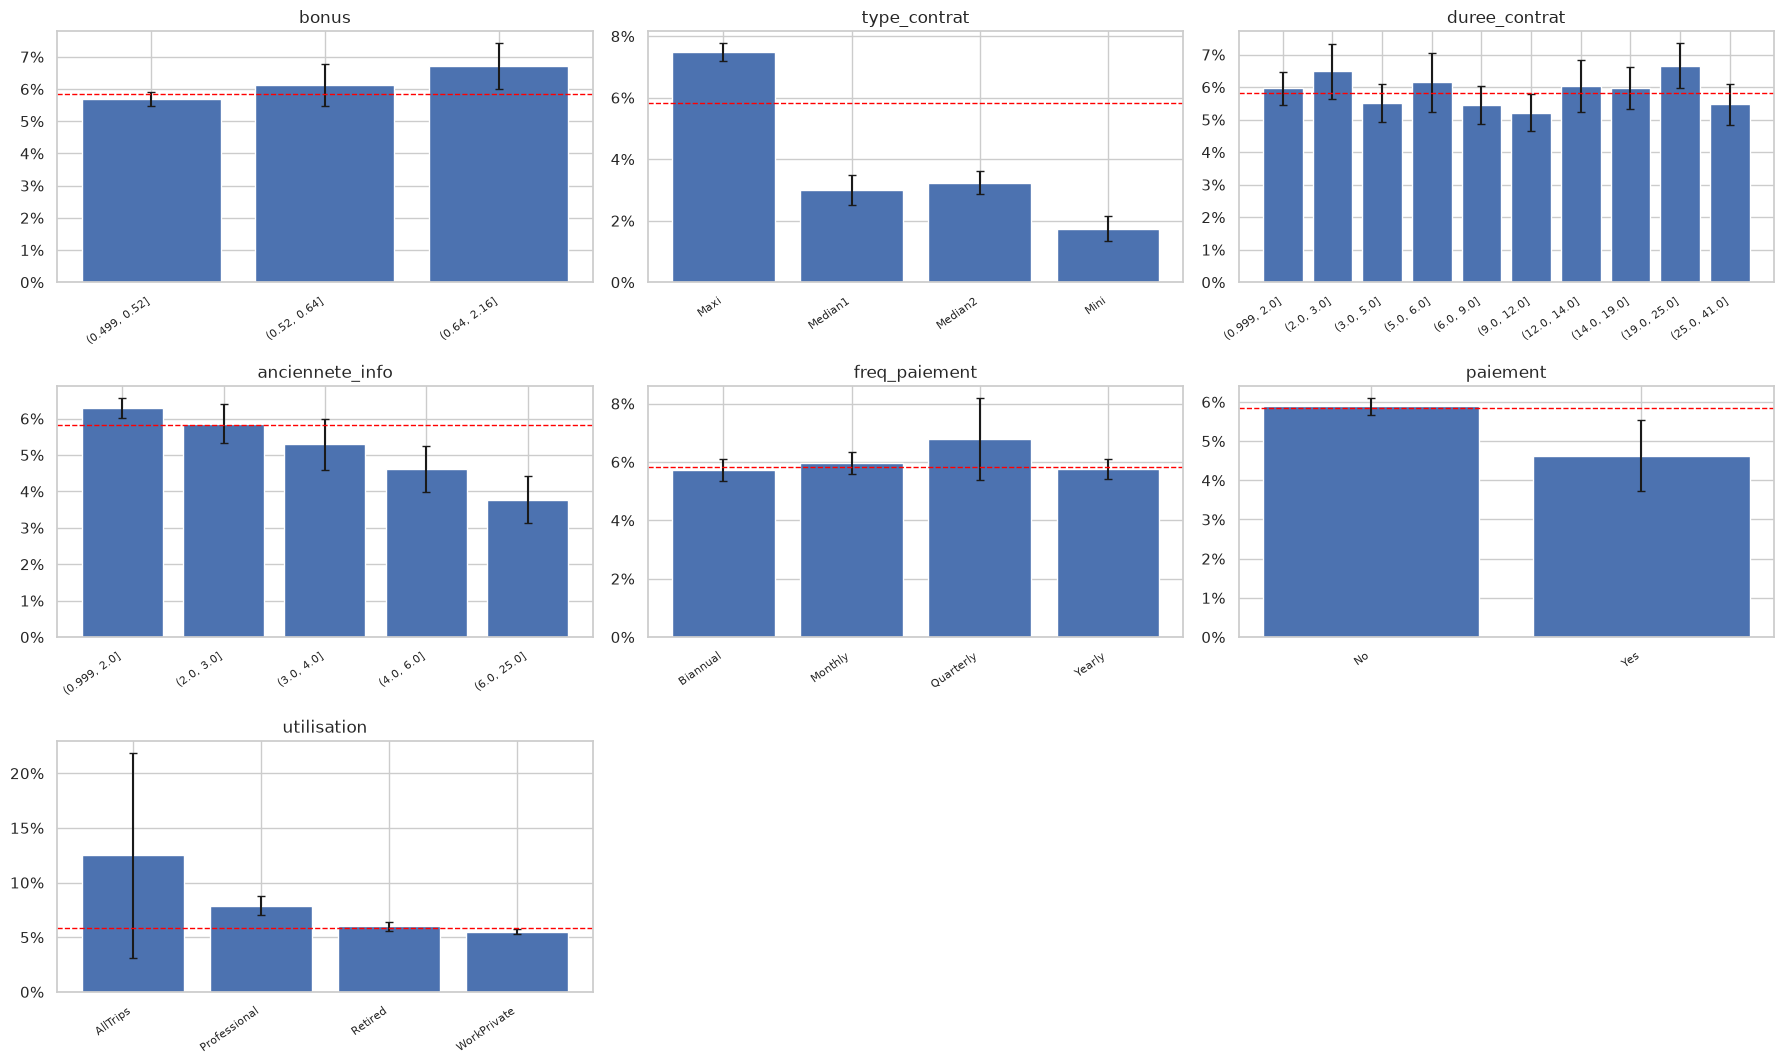

In [13]:
tracer_taux(train, VAR_CONTRAT)

### Variables liées aux conducteurs

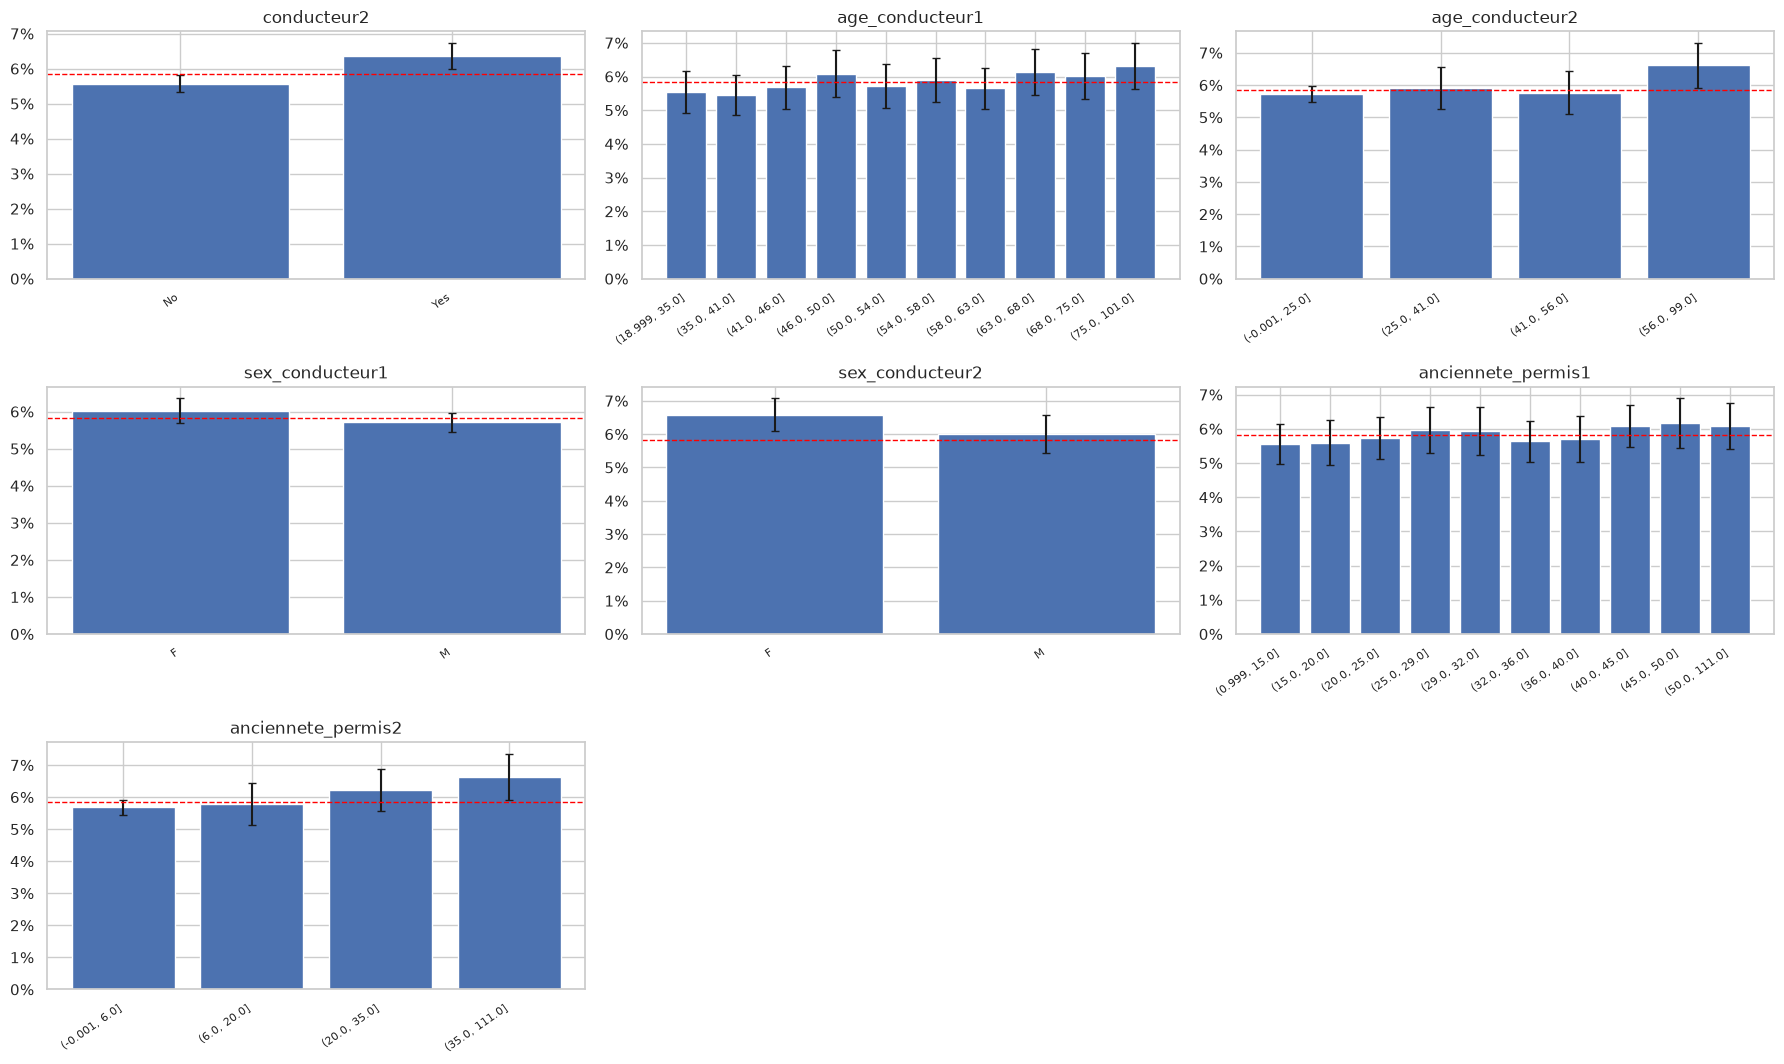

In [14]:
tracer_taux(train, VAR_CONDUCTEURS)

### Variables liées au véhicule

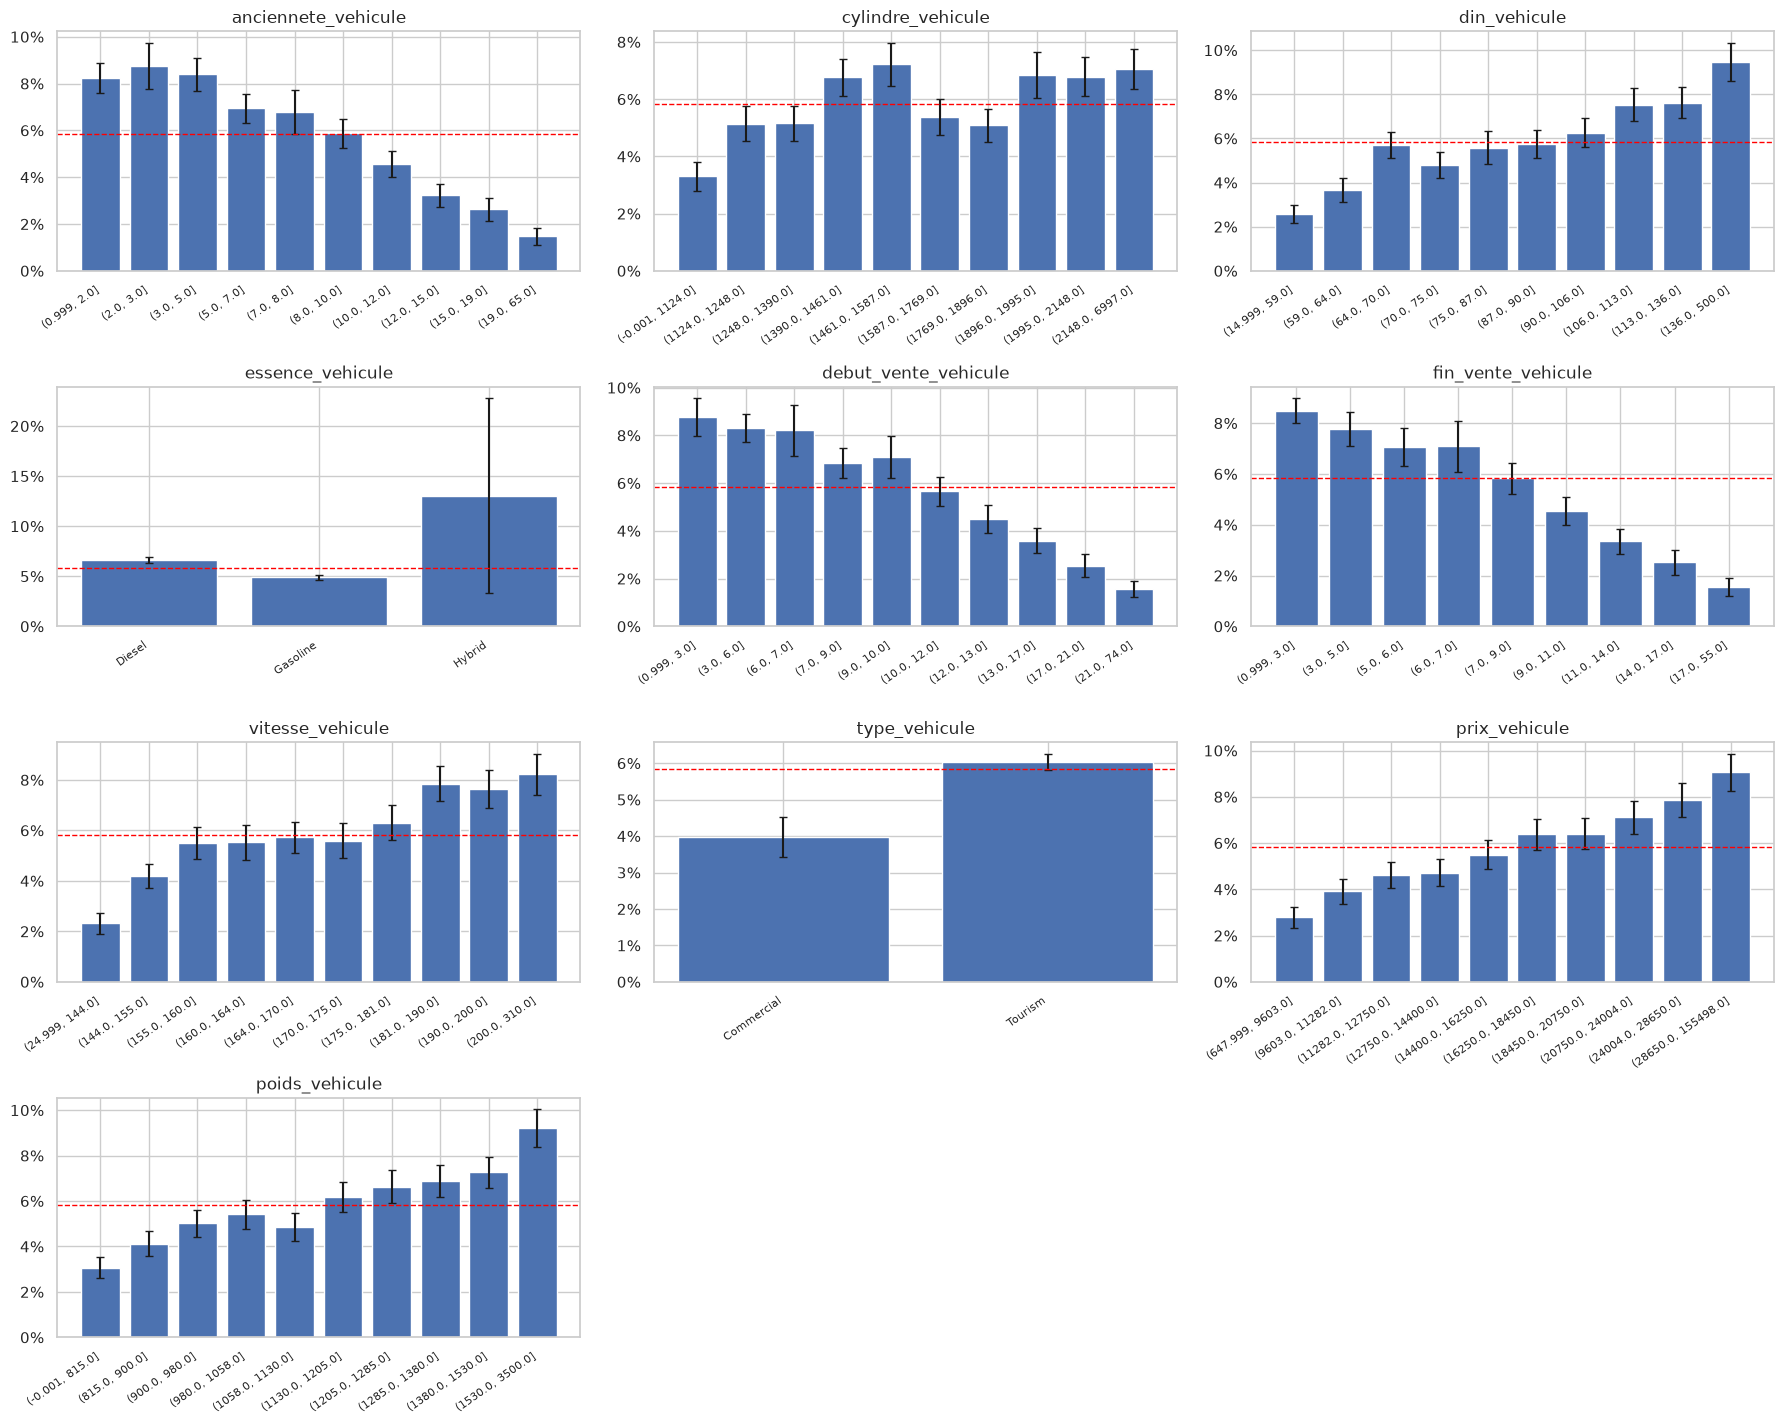

In [15]:
vehicule_peu_modalites = [c for c in VAR_VEHICULE if c not in ("marque_vehicule", "modele_vehicule")]
tracer_taux(train, vehicule_peu_modalites)

### Variables à forte cardinalité : marque et département
On n'affiche que les modalités ayant suffisamment d'observations (au moins 500 lignes), sinon les taux sont trop bruités.

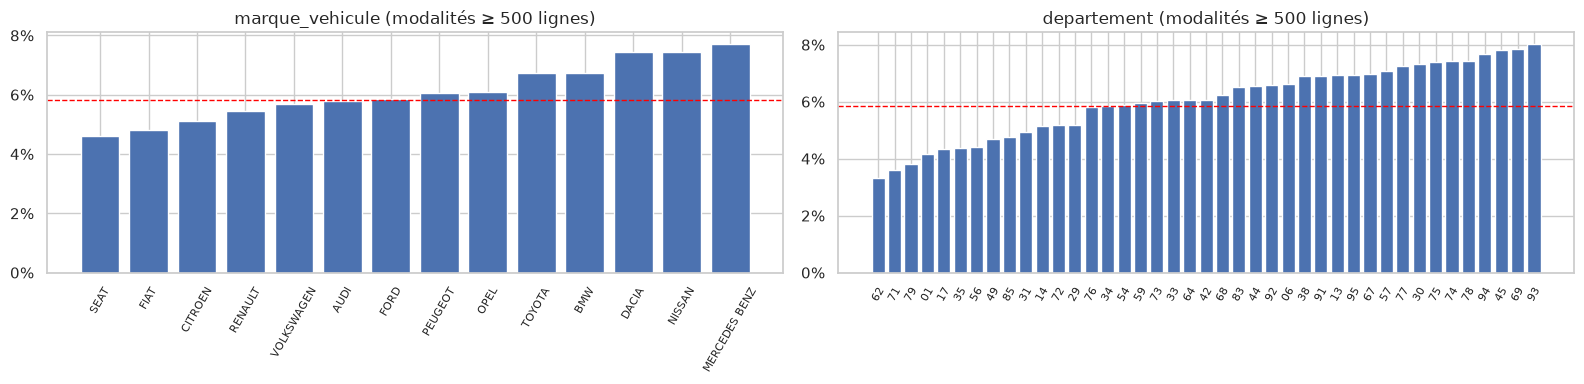

In [16]:
tmp = train.assign(departement=train["code_postal"].str[:2])

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, col in zip(axes, ["marque_vehicule", "departement"]):
    g = taux_par_classe(tmp, col)
    g = g[g["effectif"] >= 500].sort_values("taux")
    ax.bar(g.index.astype(str), g["taux"], color="#4C72B0")
    ax.axhline(taux_moyen, color="red", ls="--", lw=1)
    ax.set_title(f"{col} (modalités ≥ 500 lignes)")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
plt.tight_layout()
plt.show()

## 2.6 Redondance entre variables explicatives (multicolinéarité)

Ici, la matrice de corrélation sert à détecter les variables qui portent **la même information**. On utilise Spearman (corrélation des rangs), plus robuste aux valeurs extrêmes et aux relations non linéaires monotones.

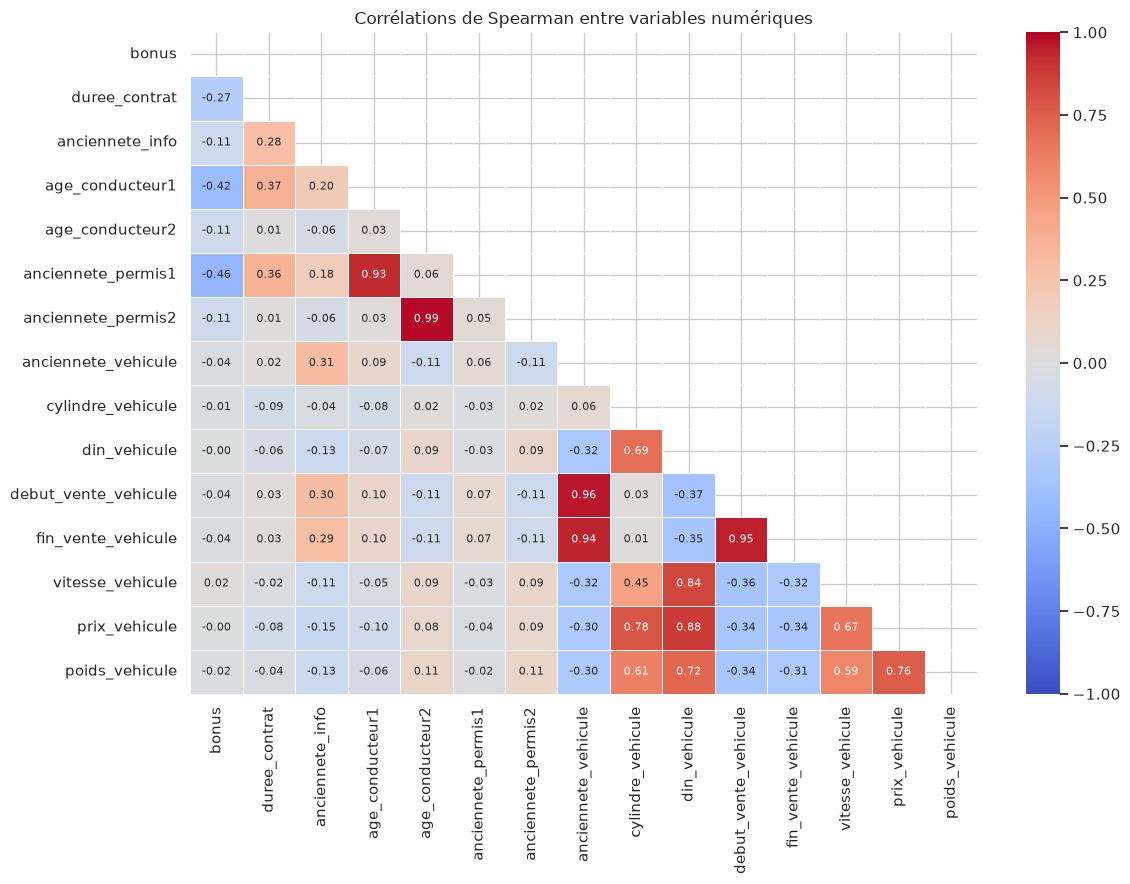

,level_0,level_1,spearman
94,anciennete_permis2,age_conducteur2,0.99
157,debut_vente_vehicule,anciennete_vehicule,0.96
175,fin_vente_vehicule,debut_vente_vehicule,0.95
172,fin_vente_vehicule,anciennete_vehicule,0.94
78,anciennete_permis1,age_conducteur1,0.93
204,prix_vehicule,din_vehicule,0.88
189,vitesse_vehicule,din_vehicule,0.84
203,prix_vehicule,cylindre_vehicule,0.78
223,poids_vehicule,prix_vehicule,0.76
219,poids_vehicule,din_vehicule,0.72


In [17]:
corr = train[numeriques].corr(method="spearman")
masque = np.triu(np.ones_like(corr, dtype=bool))  # on n'affiche que le triangle inférieur

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, linewidths=0.5, annot_kws={"size": 8})
plt.title("Corrélations de Spearman entre variables numériques")
plt.tight_layout()
plt.show()

paires = (corr.where(~masque).stack().rename("spearman").reset_index()
          .query("abs(spearman) >= 0.7").sort_values("spearman", key=abs, ascending=False))
paires.round(2)

**Constats**
- `anciennete_vehicule`, `debut_vente_vehicule` et `fin_vente_vehicule` sont quasiment redondantes (ρ ≈ 0,95) : elles mesurent toutes « l'âge » du véhicule.
- `din_vehicule`, `prix_vehicule`, `vitesse_vehicule` (et `cylindre_vehicule`) mesurent la **puissance / gamme** du véhicule (ρ entre 0,7 et 0,9).
- L'âge du conducteur et l'ancienneté de son permis sont fortement liés, de même pour le second conducteur.

**Conséquence** :
- pour la **régression logistique**, la multicolinéarité rend les coefficients instables. On retire `debut_vente_vehicule` et `fin_vente_vehicule` et on ajoute une régularisation ;
- pour les **arbres**, ce n'est pas gênant : on garde toutes les variables.

---
# Partie 3 — Préparation des données

## 3.1 Choix des variables

| Exclues | Raison |
|---|---|
| `nombre_sinistres` | Cible |
| `montant_sinistre` | Fuite directe de la cible |
| `index`, `id_client`, `id_vehicule`, `id_contrat` | Identifiants, absents du test |
| `sex_conducteur1`, `sex_conducteur2` | **Interdits** en tarification dans l'UE depuis 2012 (arrêt Test-Achats). Leur pouvoir prédictif est de toute façon quasi nul (§3.4) |
| `code_postal` brut (code commune INSEE) | Trop de modalités : remplacé par le **département** (créé au nettoyage, 3.3) |

`id_client` est conservé **à part** pour construire un découpage par client.

In [18]:
VARIABLES_EXCLUES = IDENTIFIANTS + CIBLES + ["sex_conducteur1", "sex_conducteur2"]
X_complet = train.drop(columns=VARIABLES_EXCLUES)
y_complet = train[CIBLE]
groupes = train["id_client"]
X_test_kaggle = test.drop(columns=[c for c in VARIABLES_EXCLUES if c in test.columns])

assert list(X_complet.columns) == list(X_test_kaggle.columns)
print("Variables conservées (%d) :" % X_complet.shape[1], X_complet.columns.tolist())

Variables conservées (25) : ['bonus', 'type_contrat', 'duree_contrat', 'anciennete_info', 'freq_paiement', 'paiement', 'utilisation', 'code_postal', 'conducteur2', 'age_conducteur1', 'age_conducteur2', 'anciennete_permis1', 'anciennete_permis2', 'anciennete_vehicule', 'cylindre_vehicule', 'din_vehicule', 'essence_vehicule', 'marque_vehicule', 'modele_vehicule', 'debut_vente_vehicule', 'fin_vente_vehicule', 'vitesse_vehicule', 'type_vehicule', 'prix_vehicule', 'poids_vehicule']


## 3.2 Découpage train / validation

Deux contraintes :
1. **Stratification** sur la cible : garder environ 6 % de sinistrés dans chaque jeu, sinon les résultats dépendent du hasard du tirage.
2. **Groupement par client** : environ 3 900 clients assurent plusieurs véhicules (`id_vehicule` V02 à V05). Ces lignes partagent le même conducteur et la même adresse. Si un client se retrouve à la fois en train et en validation, le modèle est évalué sur un profil qu'il a déjà vu, et la performance mesurée est **trop optimiste**.

→ On utilise `StratifiedGroupKFold` (stratifié **et** groupé) : on garde un pli sur 5 comme validation (20 %).
Le même objet servira en partie 4 pour la **validation croisée** sur le jeu d'entraînement (optimisation des hyperparamètres).

In [19]:
from sklearn.model_selection import StratifiedGroupKFold

print("Véhicules par client :", train["id_vehicule"].value_counts().to_dict())
print("Clients avec plusieurs véhicules :", (train["id_client"].value_counts() > 1).sum())

decoupage = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_train, idx_valid = next(decoupage.split(X_complet, y_complet, groups=groupes))

X_train, X_valid = X_complet.iloc[idx_train], X_complet.iloc[idx_valid]
y_train, y_valid = y_complet.iloc[idx_train], y_complet.iloc[idx_valid]
groupes_train = groupes.iloc[idx_train]

print(f"\ntrain      : {len(X_train):>6} lignes | taux de sinistres = {y_train.mean():.2%}")
print(f"validation : {len(X_valid):>6} lignes | taux de sinistres = {y_valid.mean():.2%}")

clients_communs = set(groupes.iloc[idx_train]) & set(groupes.iloc[idx_valid])
print("Clients présents dans les deux jeux :", len(clients_communs))
assert len(clients_communs) == 0

# Validation croisée réutilisable en partie 4 (sur le train uniquement)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

Véhicules par client : {'V01': 45785, 'V02': 3905, 'V03': 272, 'V04': 32, 'V05': 6}
Clients avec plusieurs véhicules : 3905



train      :  39999 lignes | taux de sinistres = 5.83%
validation :  10001 lignes | taux de sinistres = 5.84%
Clients présents dans les deux jeux : 0


## 3.3 Nettoyage

On corrige les anomalies repérées en partie 2 avec une fonction `nettoyer`, appliquée **de la même façon** au train, à la validation, aux données complètes et au test Kaggle.

| Opération | Justification |
|---|---|
| `poids_vehicule = 0` et `cylindre_vehicule = 0` → NaN | Valeurs impossibles : ce sont des valeurs manquantes déguisées, complétées à l'étape suivante |
| `code_postal` → `departement` (2 premiers caractères) | 12 790 codes communes INSEE → 96 départements (`2A` et `2B` pour la Corse) |

Ce nettoyage ne crée **pas de fuite de données** : ce sont des règles fixes, qui n'apprennent rien sur les données.

Les zéros de `age_conducteur2` et `anciennete_permis2` (pas de second conducteur) sont **conservés** : la variable `conducteur2` permet au modèle de distinguer « pas de second conducteur » d'un vrai âge.

In [20]:
def nettoyer(df):
    df = df.copy()  # on travaille sur une copie pour ne pas modifier l'original

    # 1. Un poids ou une cylindrée de 0 est impossible : c'est une valeur manquante
    df["poids_vehicule"] = df["poids_vehicule"].replace(0, np.nan)
    df["cylindre_vehicule"] = df["cylindre_vehicule"].replace(0, np.nan)

    # 2. Code commune INSEE -> département (2 premiers caractères)
    df["departement"] = df["code_postal"].str[:2]
    df = df.drop(columns=["code_postal"])

    return df


# On applique exactement le même nettoyage à tous les jeux de données
X_train = nettoyer(X_train)
X_valid = nettoyer(X_valid)
X_complet = nettoyer(X_complet)
X_test_kaggle = nettoyer(X_test_kaggle)

print("Valeurs manquantes après nettoyage (train) :")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Valeurs manquantes après nettoyage (train) :
cylindre_vehicule       3
poids_vehicule       1517
dtype: int64


## 3.4 Classement des variables : Gini univarié

On veut classer **toutes** les variables (numériques et catégorielles) selon leur capacité, **seules**, à séparer les clients risqués des autres. La corrélation ne convient pas (voir 2.5). On utilise le **Gini univarié** :
1. on découpe la variable en classes **apprises sur le train** : ses modalités si elle est catégorielle, 10 classes de même effectif si elle est continue ;
2. on calcule sur le train le **taux de sinistres lissé** de chaque classe (même formule que l'encodage de la partie 3.5, avec $m = 100$) ;
3. chaque client de la **validation** reçoit le taux de sa classe (classe inconnue : taux moyen) ;
4. on mesure le **Gini** de ce score sur la validation.

Lecture : 0 = la variable seule ne classe pas mieux que le hasard ; plus c'est haut, plus elle sépare. Un Gini proche de 0 ou légèrement négatif signifie « pas de signal ». La corrélation des variables numériques est affichée à côté, pour montrer qu'elle sous-estime le lien.

Le sexe est inclus ici **uniquement pour l'analyse** : il reste exclu du modèle (3.1).

In [21]:
def classes_apprises(x_appr, x_eval, n_classes=10):
    # Variable continue -> 10 classes de même effectif, bornes apprises sur x_appr seulement
    # Variable catégorielle (ou avec peu de valeurs) -> ses modalités, telles quelles
    if pd.api.types.is_numeric_dtype(x_appr) and x_appr.nunique() > 20:
        bornes = np.unique(x_appr.quantile(np.linspace(0, 1, n_classes + 1)))
        bornes[0], bornes[-1] = -np.inf, np.inf   # une valeur hors des bornes du train tombe dans une classe extrême
        return pd.cut(x_appr, bornes), pd.cut(x_eval, bornes)
    return x_appr, x_eval


def gini_univarie(x_appr, y_appr, x_eval, y_eval, lissage=100):
    # Gini d'une variable seule : taux lissé par classe appris sur x_appr, mesuré sur x_eval
    c_appr, c_eval = classes_apprises(x_appr, x_eval)
    stats = y_appr.groupby(c_appr, observed=True).agg(["sum", "count"])
    taux = (stats["sum"] + lissage * y_appr.mean()) / (stats["count"] + lissage)
    score = c_eval.map(taux).astype(float).fillna(y_appr.mean())  # classe inconnue -> taux moyen
    return 2 * roc_auc_score(y_eval, score) - 1


# Toutes les variables explicatives (code commune remplacé par le département), mêmes lignes que X_train / X_valid
donnees = train[explicatives].assign(departement=train["code_postal"].str[:2]).drop(columns="code_postal")
d_train, d_valid = donnees.iloc[idx_train], donnees.iloc[idx_valid]

lignes = []
for col in donnees.columns:
    c_train, _ = classes_apprises(d_train[col], d_valid[col])
    par_classe = y_train.groupby(c_train, observed=True).agg(["mean", "size"])
    par_classe = par_classe[par_classe["size"] >= 300]   # classes assez grandes pour un taux fiable
    lignes.append({
        "variable": col,
        "Gini univarié (validation)": gini_univarie(d_train[col], y_train, d_valid[col], y_valid),
        "classes": c_train.nunique(),
        "taux le plus bas (classe ≥ 300 lignes)": par_classe["mean"].min(),
        "taux le plus haut (classe ≥ 300 lignes)": par_classe["mean"].max(),
        "corrélation (train, numériques)": (d_train[col].corr(y_train)
                                            if pd.api.types.is_numeric_dtype(d_train[col]) else np.nan),
    })

classement = pd.DataFrame(lignes).set_index("variable").sort_values("Gini univarié (validation)", ascending=False)
classement.round(3)

,Gini univarié (validation),classes,taux le plus bas (classe ≥ 300 lignes),taux le plus haut (classe ≥ 300 lignes),"corrélation (train, numériques)"
variable,,,,,
fin_vente_vehicule,0.257,9,0.016,0.084,-0.096
debut_vente_vehicule,0.255,10,0.016,0.089,-0.096
anciennete_vehicule,0.240,10,0.016,0.091,-0.096
prix_vehicule,0.213,10,0.028,0.089,0.071
din_vehicule,0.213,10,0.027,0.094,0.071
type_contrat,0.212,4,0.018,0.075,NaN
vitesse_vehicule,0.182,10,0.023,0.080,0.068
poids_vehicule,0.150,10,0.028,0.093,0.062
modele_vehicule,0.144,841,0.023,0.088,NaN


### Synthèse du lien avec la fréquence

| Effet | Variables | Gini univarié (validation) | Observation (taux par classe sur le train, classes ≥ 300 lignes) |
|---|---|---|---|
| **Fort** | Âge du véhicule : `fin_vente_vehicule`, `debut_vente_vehicule`, `anciennete_vehicule` | 0,240 à 0,257 | De 1,6 % pour les véhicules les plus anciens à 8,4 – 9,1 % pour les plus récents. Hypothèse : un véhicule ancien a moins de valeur, il est moins bien assuré et moins de sinistres sont déclarés |
| **Fort** | Puissance / gamme : `prix_vehicule`, `din_vehicule`, `vitesse_vehicule`, `poids_vehicule` | 0,150 à 0,213 | De 2,3 – 2,8 % à 8,0 – 9,4 % entre les véhicules les moins et les plus puissants ou chers |
| **Fort** | `type_contrat` | 0,212 | De 1,8 % à 7,5 % selon la formule. Hypothèse : une formule « Mini » couvre moins de garanties, donc moins de sinistres sont déclarés (son coefficient est le plus négatif, voir 4.4) |
| **Moyen** | `modele_vehicule`, `cylindre_vehicule` | 0,144 et 0,081 | Le modèle de véhicule sépare bien, mais il a 841 modalités dans le train : beaucoup sont trop petites pour un taux fiable (voir le lissage, 3.5) |
| **Faible** | `anciennete_info`, `departement`, `essence_vehicule`, `duree_contrat`, `marque_vehicule`, `conducteur2`, `utilisation`, `type_vehicule` | 0,020 à 0,075 | Écarts réels mais modestes |
| **Nul** | `anciennete_permis2`, `paiement`, `bonus`, `age_conducteur2`, `freq_paiement`, `anciennete_permis1`, `age_conducteur1` | −0,047 à 0,010 | Seules, ces variables ne classent pas mieux que le hasard |

Pour comparaison, la **corrélation** de l'ancienneté du véhicule avec le sinistre n'est que de −0,096, alors que son Gini est de 0,240 et que le taux varie de 1,6 % à 9,1 % : la corrélation sous-estime bien le lien.

Le sexe n'apporte rien d'utile : Gini −0,036 pour `sex_conducteur1`, et 0,034 pour `sex_conducteur2`, qui répète surtout `conducteur2` (il est manquant exactement quand il n'y a pas de second conducteur).

À retenir pour la modélisation :
- les variables liées au **véhicule** et au **type de contrat** portent l'essentiel du signal ;
- certaines variables sont **redondantes** entre elles : les trois mesures de l'âge du véhicule ont presque le même Gini (voir 2.6) ;
- les variables **conducteur** n'ont aucun signal seules. Cela ne prouve pas qu'elles sont inutiles dans un modèle à plusieurs variables (voir 4.4) ;
- `bonus` n'a quasiment aucun signal seul (Gini 0,007), ce qui est cohérent avec l'hypothèse d'absence de fuite faite en 2.4.

## 3.5 Préparation des variables pour la régression logistique

Après le nettoyage, les données ne sont pas encore utilisables par une régression logistique :
- il reste des **valeurs manquantes** (poids, cylindrée, ancienneté du véhicule) ;
- certaines variables sont du **texte** (`type_contrat`, `marque_vehicule`…) alors que le modèle n'accepte que des nombres ;
- les variables ont des **échelles très différentes** (bonus autour de 0,5, puissance autour de 90) ;
- certaines variables sont **redondantes** (voir 2.6).

### Traitements appliqués

| Étape | Variables | Traitement | Justification |
|---|---|---|---|
| Redondance | `debut_vente_vehicule`, `fin_vente_vehicule`, `anciennete_permis1`, `age_conducteur2`, `prix_vehicule`, `vitesse_vehicule` | Retirées | Doublons d'une autre variable (corrélation ≥ 0,84) : on garde dans chaque groupe la plus corrélée au sinistre |
| Valeurs manquantes | `poids_vehicule`, `cylindre_vehicule`, `anciennete_vehicule` | Médiane du **même modèle** de véhicule, sinon de la **même marque**, sinon médiane globale | Les poids manquants sont surtout des utilitaires (Trafic, Master…), plus lourds que la moyenne : la médiane globale les sous-estimerait |
| Valeurs extrêmes | `din_vehicule`, `poids_vehicule`, `cylindre_vehicule` | Logarithme | Limiter l'influence des valeurs extrêmes |
| Pas de logarithme | `bonus` | Gardé tel quel, puis standardisé | Il ne va que de 0,5 à 2,16 : sur un intervalle aussi court, un logarithme ne change presque pas la forme de la variable. Il a donc été retiré |
| Texte, peu de modalités | `type_contrat`, `utilisation`, `essence_vehicule`… | Modalités rares (< 50 lignes) regroupées dans « Autre », puis **one-hot** (une colonne 0/1 par modalité) | Transformer le texte en nombres ; la modalité la plus fréquente sert de référence et n'a pas de colonne |
| Texte, beaucoup de modalités | `marque_vehicule`, `modele_vehicule`, `departement` | Remplacées par leur **taux de sinistres lissé** | 886 modèles de véhicule → une seule colonne au lieu de 886 |
| Échelle | Toutes les variables numériques | **Standardisation** : moyenne 0, écart-type 1 | Mettre les variables à la même échelle ; les colonnes 0/1 restent telles quelles |

### Le taux de sinistres lissé
Chaque modalité est remplacée par son taux de sinistres, ramené vers le taux moyen quand elle a peu de lignes :

$$\text{valeur} = \frac{\text{nombre de sinistres} + m \times \text{taux moyen}}{\text{nombre de lignes} + m} \quad \text{avec } m = 100$$

- Département 59 (2 265 lignes) : on garde à peu près son taux observé.
- Département 2B (8 lignes, 0 sinistre) : on le ramène vers la moyenne, car 8 lignes ne prouvent rien.
- Modalité absente du train (modèles du test inconnus) : elle reçoit le taux moyen.
- **Pour le train**, le taux est calculé **« hors pli »** : on découpe le train en 5 paquets **de clients** (tous les véhicules d'un même client tombent dans le même paquet, comme pour le découpage train / validation), et chaque ligne reçoit le taux calculé sur les 4 autres paquets. Sinon, le taux d'une ligne inclurait sa propre réponse (`nombre_sinistres`), et le modèle apprendrait à « tricher » sur le train. Pour la validation et le test, on utilise le taux calculé sur tout le train.

### Règle : apprendre sur le train uniquement
Le code est découpé en deux temps :
1. `apprendre(X_train, y_train)` calcule **sur le train seulement** les médianes, les taux de sinistres, les modalités fréquentes, les moyennes et les écarts-types ;
2. `preparer(X, params)` **applique** ces paramètres, sans rien recalculer, au train, à la validation et au test Kaggle.

Si ces paramètres étaient calculés en incluant la validation, de l'information sur la validation fuirait dans l'apprentissage et les performances mesurées seraient trop optimistes.

In [22]:
# --- Les groupes de colonnes ---------------------------------------------------
REDONDANTES = ["debut_vente_vehicule", "fin_vente_vehicule",   # doublons de anciennete_vehicule
               "anciennete_permis1",                            # doublon de age_conducteur1
               "age_conducteur2",                               # doublon de anciennete_permis2
               "prix_vehicule", "vitesse_vehicule"]             # doublons de din_vehicule

A_IMPUTER = ["poids_vehicule", "cylindre_vehicule", "anciennete_vehicule"]
QUEUE_LOURDE = ["din_vehicule", "poids_vehicule", "cylindre_vehicule"]  # bonus : pas de log (0,5 à 2,16)
CAT_FAIBLE = ["type_contrat", "freq_paiement", "paiement", "utilisation",
              "conducteur2", "essence_vehicule", "type_vehicule"]
CAT_FORTE = ["marque_vehicule", "modele_vehicule", "departement"]

SEUIL_RARE = 50   # une modalité avec moins de 50 lignes est regroupée dans "Autre"
LISSAGE = 100     # force du lissage du taux de sinistres


# --- Taux de sinistres « hors pli », pour le train uniquement -----------------
def plis_par_client(X, nb_plis=5):
    # Tire un paquet (0 à 4) par CLIENT : tous les véhicules d'un client tombent dans le
    # même paquet, comme pour le découpage train / validation.
    # `groupes` (id_client) a le même index que les lignes du train.
    clients = groupes.loc[X.index]
    paquet_du_client = pd.Series(np.random.RandomState(SEED).randint(0, nb_plis, clients.nunique()),
                                 index=clients.unique())
    return clients.map(paquet_du_client).values


def taux_hors_pli(X, y, col, lissage=LISSAGE, nb_plis=5):
    # Chaque ligne reçoit le taux calculé sur les 4 AUTRES paquets de clients : elle ne voit
    # donc jamais sa propre réponse, ni celle des autres véhicules de son client.
    pli = plis_par_client(X, nb_plis)
    taux_moyen = y.mean()
    resultat = pd.Series(np.nan, index=X.index)
    for k in range(nb_plis):
        autres = pli != k
        stats = y[autres].groupby(X.loc[autres, col]).agg(["sum", "count"])
        taux = (stats["sum"] + lissage * taux_moyen) / (stats["count"] + lissage)
        resultat[~autres] = X.loc[~autres, col].map(taux).fillna(taux_moyen).values
    return resultat


# --- 1. APPRENDRE les paramètres, sur le train UNIQUEMENT --------------------
def apprendre(X, y, lissage=LISSAGE, redondantes=REDONDANTES):
    # lissage et redondantes ont mes valeurs habituelles par défaut ; on les change seulement
    # pour les tests de la partie 4
    p = {"lissage": lissage, "redondantes": redondantes}

    # Imputation : médiane par modèle, sinon par marque, sinon médiane globale
    for col in A_IMPUTER:
        p[f"med_modele_{col}"] = X.groupby("modele_vehicule")[col].median()
        p[f"med_marque_{col}"] = X.groupby("marque_vehicule")[col].median()
        p[f"med_globale_{col}"] = X[col].median()

    # Modalités fréquentes (les autres seront regroupées dans "Autre")
    for col in CAT_FAIBLE:
        effectifs = X[col].value_counts()
        p[f"frequentes_{col}"] = effectifs[effectifs >= SEUIL_RARE].index
        p[f"reference_{col}"] = effectifs.index[0]  # modalité la plus fréquente = référence

    # Taux de sinistres par modalité, lissé vers le taux moyen (servira à valid / test)
    taux_moyen = y.mean()
    p["taux_moyen"] = taux_moyen
    for col in CAT_FORTE:
        stats = y.groupby(X[col]).agg(["sum", "count"])
        p[f"taux_{col}"] = (stats["sum"] + lissage * taux_moyen) / (stats["count"] + lissage)

    # Colonnes produites sur le train (pour que valid et test aient les mêmes)
    X_t = transformer(X, p, y)
    p["colonnes"] = X_t.columns

    # Moyennes et écarts-types pour la standardisation
    colonnes_num = [c for c in X_t.columns if X_t[c].nunique() > 2]  # on ne standardise pas les 0/1
    p["colonnes_num"] = colonnes_num
    p["moyennes"] = X_t[colonnes_num].mean()
    p["ecarts_types"] = X_t[colonnes_num].std()
    return p


# --- 2. APPLIQUER les paramètres (sans standardisation) ----------------------
def transformer(X, p, y=None):
    X = X.copy()

    # Retirer les variables redondantes
    X = X.drop(columns=p["redondantes"])

    # Imputation : modèle -> marque -> globale
    for col in A_IMPUTER:
        X[col] = X[col].fillna(X["modele_vehicule"].map(p[f"med_modele_{col}"]))
        X[col] = X[col].fillna(X["marque_vehicule"].map(p[f"med_marque_{col}"]))
        X[col] = X[col].fillna(p[f"med_globale_{col}"])

    # Log sur les variables à valeurs extrêmes
    for col in QUEUE_LOURDE:
        X[col] = np.log1p(X[col])

    # Taux de sinistres
    for col in CAT_FORTE:
        if y is not None:
            # train : taux hors pli (la ligne ne voit pas sa propre réponse)
            X[col] = taux_hors_pli(X, y, col, p["lissage"])
        else:
            # validation / test : taux du train (modalité inconnue -> taux moyen)
            X[col] = X[col].map(p[f"taux_{col}"]).fillna(p["taux_moyen"])

    # Regrouper les modalités rares, puis one-hot
    for col in CAT_FAIBLE:
        X[col] = X[col].where(X[col].isin(p[f"frequentes_{col}"]), "Autre")
    X = pd.get_dummies(X, columns=CAT_FAIBLE, dtype=int)
    # On retire la colonne de la modalité de référence (sinon les colonnes d'une
    # même variable somment toujours à 1 : redondance parfaite)
    X = X.drop(columns=[f"{col}_{p[f'reference_{col}']}" for col in CAT_FAIBLE], errors="ignore")

    # Mêmes colonnes que le train (une modalité absente -> colonne de 0)
    if "colonnes" in p:
        X = X.reindex(columns=p["colonnes"], fill_value=0)
    return X


def preparer(X, p, y=None):
    X = transformer(X, p, y)
    X[p["colonnes_num"]] = (X[p["colonnes_num"]] - p["moyennes"]) / p["ecarts_types"]
    return X


params = apprendre(X_train, y_train)               # appris sur le train SEULEMENT

X_train_prep = preparer(X_train, params, y_train)  # train : taux hors pli
X_valid_prep = preparer(X_valid, params)           # paramètres du train réutilisés
X_test_prep = preparer(X_test_kaggle, params)

print("train :", X_train_prep.shape, "| valid :", X_valid_prep.shape, "| test :", X_test_prep.shape)
X_train_prep.head()

train : (39999, 26) | valid : (10001, 26) | test : (50000, 26)


,bonus,duree_contrat,anciennete_info,age_conducteur1,anciennete_permis2,anciennete_vehicule,cylindre_vehicule,din_vehicule,marque_vehicule,modele_vehicule,poids_vehicule,departement,type_contrat_Median1,type_contrat_Median2,type_contrat_Mini,freq_paiement_Biannual,freq_paiement_Monthly,freq_paiement_Quarterly,paiement_Yes,utilisation_Autre,utilisation_Professional,utilisation_Retired,conducteur2_Yes,essence_vehicule_Autre,essence_vehicule_Gasoline,type_vehicule_Commercial
0,-0.382988,2.083605,2.658706,2.038424,-0.536221,0.066031,0.002150,0.370793,0.251001,-1.520135,0.177141,-0.267104,0,0,0,1,0,0,0,0,0,1,0,0,1,0
1,-0.382988,-0.946827,-0.736693,0.963213,-0.536221,-0.786463,1.085361,1.928672,1.239342,0.325141,1.061027,0.952650,0,0,0,1,0,0,0,0,0,1,0,0,0,0
2,-0.382988,-1.063382,-0.312268,-1.187209,-0.536221,0.208113,0.812483,1.574126,1.160933,0.873568,0.370262,0.911628,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,-0.382988,0.568389,0.536582,0.492808,2.267195,0.208113,0.026829,0.645083,-0.048458,0.586496,0.242558,0.610880,0,0,0,1,0,0,0,0,0,1,1,0,1,0
6,-0.382988,-0.713717,0.112157,1.500819,-0.536221,-0.360216,0.588449,0.645083,-0.048458,0.586496,0.614036,0.610880,0,0,0,1,0,0,0,0,0,1,0,0,0,0


## 3.6 Vérifications

Avant de passer à la modélisation, on vérifie que la préparation a bien fonctionné :
1. les trois jeux ont le même format, sans valeur manquante ;
2. l'imputation des poids donne des valeurs cohérentes ;
3. les paramètres ont bien été appris sur le train uniquement ;
4. les modalités inconnues du test sont bien gérées ;
5. les taux de sinistres ne « trichent » pas sur le train.

### 1. Même format, sans valeur manquante

In [23]:
print("Mêmes colonnes train / valid :", list(X_train_prep.columns) == list(X_valid_prep.columns))
print("Mêmes colonnes train / test  :", list(X_train_prep.columns) == list(X_test_prep.columns))
print("Valeurs manquantes (train, valid, test) :",
      X_train_prep.isna().sum().sum(), X_valid_prep.isna().sum().sum(), X_test_prep.isna().sum().sum())
print("Colonnes non numériques :", X_train_prep.select_dtypes(exclude="number").columns.tolist())

Mêmes colonnes train / valid : True
Mêmes colonnes train / test  : True
Valeurs manquantes (train, valid, test) : 0 0 0
Colonnes non numériques : []


### 2. Imputation des poids manquants
On regarde le poids attribué aux véhicules dont le poids était manquant, pour les modèles les plus concernés.

In [24]:
manquants = X_train.loc[X_train["poids_vehicule"].isna(), ["modele_vehicule"]].copy()
# on reprend les données avant standardisation, et on annule le log pour retrouver des kg
manquants["poids imputé (kg)"] = np.expm1(
    transformer(X_train, params, y_train).loc[manquants.index, "poids_vehicule"]).round()

display(manquants.groupby("modele_vehicule")["poids imputé (kg)"]
        .agg(["count", "median"]).sort_values("count", ascending=False).head(5))
print("Poids médian global du train :", X_train["poids_vehicule"].median(), "kg")

,count,median
modele_vehicule,,
TRAFIC,240,1845.0
MASTER,142,1887.0
TRANSIT,114,1670.0
BOXER,94,1885.0
VITO,77,2600.0


Poids médian global du train : 1145.0 kg


### 3. Paramètres appris sur le train uniquement
Les variables numériques doivent avoir une moyenne de 0 et un écart-type de 1 **sur le train**. Sur la validation, elles doivent en être **proches sans être exactement égales** : cela prouve que la validation a été transformée avec les paramètres du train, sans les recalculer.

In [25]:
print("Taux moyen retenu :", round(params["taux_moyen"], 4), "| taux du train :", round(y_train.mean(), 4))

comparaison = pd.DataFrame({
    "moyenne train": X_train_prep[params["colonnes_num"]].mean(),
    "écart-type train": X_train_prep[params["colonnes_num"]].std(),
    "moyenne validation": X_valid_prep[params["colonnes_num"]].mean(),
    "écart-type validation": X_valid_prep[params["colonnes_num"]].std(),
}).round(3)
comparaison

Taux moyen retenu : 0.0583 | taux du train : 0.0583


,moyenne train,écart-type train,moyenne validation,écart-type validation
bonus,0.0,1.0,0.001,1.002
duree_contrat,-0.0,1.0,-0.019,0.993
anciennete_info,-0.0,1.0,-0.019,0.984
age_conducteur1,0.0,1.0,-0.006,0.995
anciennete_permis2,-0.0,1.0,-0.012,0.982
anciennete_vehicule,-0.0,1.0,-0.003,0.981
cylindre_vehicule,0.0,1.0,0.002,0.981
din_vehicule,-0.0,1.0,0.008,1.000
marque_vehicule,-0.0,1.0,0.011,0.988
modele_vehicule,0.0,1.0,-0.013,1.052


### 4. Modalités inconnues du test
Certains modèles de véhicule du test n'existent pas dans le train : ils doivent recevoir le taux moyen.

In [26]:
inconnus = ~X_test_kaggle["modele_vehicule"].isin(params["taux_modele_vehicule"].index)
print("Lignes du test avec un modèle inconnu du train :", inconnus.sum())
print("Valeur reçue (avant standardisation) :",
      transformer(X_test_kaggle, params).loc[inconnus, "modele_vehicule"].unique().round(4))

Lignes du test avec un modèle inconnu du train : 258


Valeur reçue (avant standardisation) : [0.0583]


### 5. Les taux de sinistres ne trichent pas
Si le taux d'une ligne incluait sa propre réponse, la colonne serait beaucoup plus corrélée au sinistre sur le train que sur la validation.

In [27]:
pd.DataFrame({
    "corrélation train": X_train_prep[CAT_FORTE].corrwith(y_train),
    "corrélation validation": X_valid_prep[CAT_FORTE].corrwith(y_valid),
}).round(3)

,corrélation train,corrélation validation
marque_vehicule,0.023,0.016
modele_vehicule,0.063,0.059
departement,0.021,0.029


### Bilan des vérifications
- Les trois jeux ont **les mêmes 26 colonnes**, toutes numériques, **sans aucune valeur manquante**.
- Les poids imputés sont **cohérents** : 1 845 kg pour un Trafic et 1 887 kg pour un Master, contre une médiane globale de 1 145 kg. Une imputation par la médiane globale aurait fortement sous-estimé le poids de ces utilitaires.
- Les variables numériques ont une moyenne de 0 et un écart-type de 1 sur le train, et des valeurs **proches mais pas identiques** sur la validation : les paramètres ont bien été appris **sur le train uniquement**.
- Les 258 lignes du test avec un modèle de véhicule inconnu reçoivent le **taux moyen** (0,0583).
- Grâce au calcul hors pli (par paquets de clients), les taux de sinistres ont **presque la même corrélation sur le train et sur la validation** (0,063 contre 0,059 pour le modèle de véhicule, 0,023 contre 0,016 pour la marque, 0,021 contre 0,029 pour le département) : ils n'apportent pas de fausse information au modèle.

## 3.7 Conclusion de la préparation : données disponibles pour la partie 4

### Les tableaux prêts pour le modèle

| Objet | Lignes | Contenu |
|---|---|---|
| `X_train_prep`, `y_train` | 39 999 (80 %) | Variables préparées et cible, pour **entraîner** le modèle |
| `X_valid_prep`, `y_valid` | 10 001 (20 %) | Variables préparées et cible, pour **évaluer** le modèle sur des clients jamais vus |
| `X_test_prep` | 50 000 | Variables préparées du test Kaggle, pour **prédire** et soumettre |

Les trois tableaux ont **les mêmes 26 colonnes**, uniquement numériques et sans valeur manquante :
- **12 colonnes numériques standardisées**, dont les 3 taux de sinistres (`marque_vehicule`, `modele_vehicule`, `departement`) ;
- **14 colonnes 0/1** issues du one-hot (par exemple `type_contrat_Mini`, `freq_paiement_Monthly`), chacune à lire par rapport à la modalité de référence de sa variable.

### Les autres objets utiles

| Objet | Utilité |
|---|---|
| `params` | Tout ce qui a été appris sur le train (médianes, taux, moyennes, écarts-types) |
| `apprendre`, `preparer` | Les fonctions de préparation, à réutiliser telles quelles |
| `X_complet`, `y_complet` | Toutes les données d'entraînement (déjà nettoyées), pour le **réentraînement final** avant la soumission Kaggle |
| `test["index"]` | Identifiant de chaque ligne du test, pour le fichier de soumission |

### Pour l'export final (fin de la partie 4)
On réapprend les paramètres sur **toutes** les données d'entraînement (`X_complet`), puis on prépare le test avec ces nouveaux paramètres : c'est fait dans la dernière section du notebook.

---
# Partie 4 — Modélisation de la fréquence

Objectif : prédire pour chaque client la **probabilité d'avoir au moins un sinistre**.

Démarche :
1. choisir une **métrique** adaptée ;
2. établir des **références** simples (taux moyen, puis régression logistique) ;
3. **optimiser** la régularisation, puis tester le traitement du véhicule et le choix des variables ;
4. **comparer** train et validation, puis conclure (sous- ou sur-apprentissage, gain par rapport à la référence).

## 4.1 Choix de la métrique

### Les classes sont déséquilibrées : l'accuracy est trompeuse
Il y a environ 94 % de non-sinistrés pour 6 % de sinistrés. Un modèle qui prédit « aucun sinistre » pour tout le monde obtient environ **94 % de bonnes réponses** (accuracy) sans rien avoir appris. L'accuracy ne permet donc pas de distinguer un bon modèle d'un modèle inutile.

### La probabilité doit être juste, pas seulement bien ordonnée
La probabilité prédite sera **multipliée par un montant** pour calculer la prime. Si le modèle annonce 12 % au lieu de 6 %, la prime est deux fois trop chère. Il faut donc une métrique qui vérifie que la probabilité est juste **en valeur** (on dit qu'elle est **bien calibrée**).

### Métriques retenues

| Métrique | Ce qu'elle mesure | Lecture |
|---|---|---|
| **Log-loss** (métrique principale) | L'erreur entre la probabilité prédite et ce qui s'est passé : $-\ln(\text{probabilité donnée à ce qui s'est réellement passé})$, en moyenne sur les clients. Elle pénalise fortement un modèle sûr de lui qui se trompe | Plus c'est **bas**, mieux c'est |
| **Score de Brier** | L'erreur quadratique moyenne entre la probabilité prédite et la réalité (0 ou 1) | Plus c'est **bas**, mieux c'est |
| **AUC / Gini** | La capacité à **classer** les clients du moins au plus risqué. L'AUC est la probabilité qu'un sinistré tiré au hasard ait un score plus élevé qu'un non-sinistré tiré au hasard. Gini $= 2 \times AUC - 1$ | 0 = hasard, 1 = classement parfait |

La log-loss et le Brier vérifient la **calibration**, indispensable pour la prime. L'AUC/Gini vérifie seulement le **classement** : un modèle qui doublerait toutes les probabilités aurait le même Gini, mais une très mauvaise log-loss. On choisit donc les modèles avec la **log-loss**, et le Gini sert de complément.

> ⚠️ **MÉTRIQUE KAGGLE À VÉRIFIER.** La page *Evaluation* de la compétition Kaggle n'a pas été consultée : nous ne connaissons pas la métrique officielle du classement.
> Kaggle note la **prime** (probabilité × montant), pas seulement notre probabilité. La log-loss est notre critère pour le modèle de fréquence ; il faudra vérifier qu'il est cohérent avec la métrique officielle avant de conclure sur le score Kaggle.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score


def evaluer(y, proba):
    # Les trois métriques retenues pour une probabilité prédite
    auc = roc_auc_score(y, proba)
    return {"log-loss": log_loss(y, proba),
            "Brier": brier_score_loss(y, proba),
            "Gini": 2 * auc - 1}

## 4.2 Références (baselines)

Le score d'un modèle n'a de sens que comparé à une référence. On en établit deux :
1. **Le taux moyen** : prédire 5,8 % (taux de sinistres du train) pour tout le monde, sans regarder aucune variable. C'est le modèle le plus simple possible : un modèle utile doit faire mieux.
2. **La régression logistique** avec ses réglages par défaut : le modèle linéaire de référence pour une probabilité.

### Référence 1 : le taux moyen

In [29]:
taux_moyen_train = y_train.mean()
proba_ref_train = np.full(len(y_train), taux_moyen_train)
proba_ref_valid = np.full(len(y_valid), taux_moyen_train)

# Illustration du piège de l'accuracy : prédire « aucun sinistre » pour tout le monde
accuracy_ref = (y_valid == 0).mean()
print(f"Accuracy du modèle « aucun sinistre » : {accuracy_ref:.1%}  <- élevée, mais le modèle n'a rien appris")

resultats = {}  # on y range les scores de chaque modèle, sur le train et la validation
resultats["Taux moyen"] = {"train": evaluer(y_train, proba_ref_train),
                           "validation": evaluer(y_valid, proba_ref_valid)}
pd.DataFrame(resultats["Taux moyen"]).T.round(4)

Accuracy du modèle « aucun sinistre » : 94.2%  <- élevée, mais le modèle n'a rien appris


,log-loss,Brier,Gini
train,0.2223,0.0549,0.0
validation,0.2225,0.0550,0.0


→ Le taux moyen a un Gini de 0 : il ne classe personne. Sa log-loss (≈ 0,222) est **le score à battre**.

### Référence 2 : la régression logistique (réglages par défaut)

La régression logistique calcule, pour chaque client, un **score** = somme pondérée de ses 26 variables, puis transforme ce score en probabilité entre 0 et 1. Pendant l'entraînement, elle cherche les poids (**coefficients**) qui rendent les probabilités prédites les plus proches des sinistres observés sur le train.

In [30]:
reg_log_defaut = LogisticRegression(max_iter=2000)
reg_log_defaut.fit(X_train_prep, y_train)

resultats["Régression logistique (défaut)"] = {
    "train": evaluer(y_train, reg_log_defaut.predict_proba(X_train_prep)[:, 1]),
    "validation": evaluer(y_valid, reg_log_defaut.predict_proba(X_valid_prep)[:, 1]),
}
pd.DataFrame(resultats["Régression logistique (défaut)"]).T.round(4)

,log-loss,Brier,Gini
train,0.2135,0.0540,0.3104
validation,0.2138,0.0542,0.3127


→ La régression logistique fait **mieux que le taux moyen** en validation (log-loss plus basse, Gini nettement positif) : les variables apportent une vraie information. Les scores train et validation sont proches : pas de sur-apprentissage.

## 4.3 Optimisation des hyperparamètres

### Pourquoi une validation croisée ?
Un **hyperparamètre** est un réglage du modèle qu'on choisit avant l'entraînement (par exemple la force de la régularisation). Pour le choisir, on compare plusieurs valeurs.

On ne peut pas les comparer sur le jeu de validation : à force de choisir ce qui marche le mieux sur la validation, on finirait par « apprendre » la validation, et son score ne serait plus une estimation honnête. On garde donc la validation pour la **fin**, et on compare les réglages par **validation croisée sur le train** :
- on découpe le train en 5 paquets (plis), **par client** et en gardant 6 % de sinistrés dans chacun (`cv`, défini en 3.2) ;
- 5 fois de suite, on entraîne sur 4 paquets et on évalue sur le 5ᵉ ;
- on fait la moyenne des 5 scores.

**Point important** : dans chaque pli, la préparation (`apprendre`) est refaite sur les 4 paquets d'entraînement seulement. Sinon, les médianes, taux et moyennes contiendraient de l'information sur le paquet d'évaluation.

On prépare les 5 plis une seule fois, puis on les réutilise pour tous les modèles testés.

In [31]:
plis = []
for positions_entr, positions_eval in cv.split(X_train, y_train, groups=groupes_train):
    X_entr, X_eval = X_train.iloc[positions_entr], X_train.iloc[positions_eval]
    y_entr, y_eval = y_train.iloc[positions_entr], y_train.iloc[positions_eval]

    params_pli = apprendre(X_entr, y_entr)  # préparation apprise sur les 4 paquets seulement
    plis.append((preparer(X_entr, params_pli, y_entr), y_entr,
                 preparer(X_eval, params_pli), y_eval))

print("Nombre de plis :", len(plis))
for i, (_, y_entr, _, y_eval) in enumerate(plis, 1):
    print(f"pli {i} : {len(y_entr)} lignes d'entraînement, {len(y_eval)} d'évaluation, "
          f"taux de sinistres en évaluation = {y_eval.mean():.2%}")


def log_loss_cv(creer_modele):
    # Log-loss moyenne sur les 5 plis pour un modèle donné
    scores = []
    for X_entr, y_entr, X_eval, y_eval in plis:
        modele = creer_modele()
        modele.fit(X_entr, y_entr)
        scores.append(log_loss(y_eval, modele.predict_proba(X_eval)[:, 1]))
    return np.mean(scores), np.std(scores)

Nombre de plis : 5
pli 1 : 31999 lignes d'entraînement, 8000 d'évaluation, taux de sinistres en évaluation = 5.84%
pli 2 : 31998 lignes d'entraînement, 8001 d'évaluation, taux de sinistres en évaluation = 5.84%
pli 3 : 32000 lignes d'entraînement, 7999 d'évaluation, taux de sinistres en évaluation = 5.83%
pli 4 : 31999 lignes d'entraînement, 8000 d'évaluation, taux de sinistres en évaluation = 5.84%
pli 5 : 32000 lignes d'entraînement, 7999 d'évaluation, taux de sinistres en évaluation = 5.83%


### Optimisation de la régression logistique : la régularisation `C`

La **régularisation** empêche les coefficients de devenir trop grands, ce qui limite le sur-apprentissage.
- `C` petit : régularisation **forte**, coefficients écrasés vers 0, modèle très prudent (risque de sous-apprentissage) ;
- `C` grand : régularisation **faible**, le modèle colle davantage aux données du train (risque de sur-apprentissage).

Par défaut, `C = 1`.

In [32]:
lignes = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    moyenne, ecart = log_loss_cv(lambda: LogisticRegression(C=C, max_iter=2000))
    lignes.append({"C": C, "log-loss CV (moyenne)": moyenne, "écart-type entre plis": ecart})

recherche_reg_log = pd.DataFrame(lignes).set_index("C")
meilleur_C = recherche_reg_log["log-loss CV (moyenne)"].idxmin()
print("Meilleur C :", meilleur_C)
entre = recherche_reg_log.loc[0.1:10, "log-loss CV (moyenne)"]
print(f"Entre C = 0,1 et C = 10 : log-loss CV de {entre.min():.5f} à {entre.max():.5f}")
recherche_reg_log.round(5)

Meilleur C : 0.1
Entre C = 0,1 et C = 10 : log-loss CV de 0.21427 à 0.21429


,log-loss CV (moyenne),écart-type entre plis
C,,
0.001,0.21568,0.00064
0.010,0.21444,0.00092
0.100,0.21427,0.00098
1.000,0.21429,0.00100
10.000,0.21429,0.00100


→ **La régularisation n'est pas le levier.** Entre C = 0,1 et C = 10, la log-loss CV ne varie que de 0,21427 à 0,21429, soit un écart 50 fois plus petit que l'écart-type entre plis (environ 0,001). Avec environ 32 000 lignes d'entraînement par pli pour 26 colonnes, les coefficients sont bien estimés même sans contrainte. Seule une régularisation très forte (C = 0,001) dégrade le modèle (0,21568), car elle écrase les coefficients vers 0.

On garde C = 0,1, le meilleur (à égalité avec C = 1 et C = 10). Pour améliorer le modèle, il faudra chercher du côté des **variables** (4.5 et 4.6), pas du réglage.

## 4.4 Comparaison train / validation et conclusion

On réentraîne la régression logistique sur **tout le train** avec le meilleur `C`, puis on l'évalue **une seule fois** sur la validation.

In [33]:
reg_log = LogisticRegression(C=meilleur_C, max_iter=2000)
reg_log.fit(X_train_prep, y_train)

resultats[f"Régression logistique (C = {meilleur_C})"] = {
    "train": evaluer(y_train, reg_log.predict_proba(X_train_prep)[:, 1]),
    "validation": evaluer(y_valid, reg_log.predict_proba(X_valid_prep)[:, 1]),
}

# Tableau récapitulatif : une ligne par modèle, train et validation côte à côte
tableau = pd.concat({nom: pd.DataFrame(scores).T.stack() for nom, scores in resultats.items()}, axis=1).T
tableau.columns = [f"{metrique} ({jeu})" for jeu, metrique in tableau.columns]
colonnes = [f"{m} ({j})" for m in ["log-loss", "Brier", "Gini"] for j in ["train", "validation"]]
tableau = tableau[colonnes]

ref = tableau.loc["Taux moyen", "log-loss (validation)"]
tableau["gain de log-loss vs taux moyen (validation)"] = (1 - tableau["log-loss (validation)"] / ref)
tableau.round(4)

,log-loss (train),log-loss (validation),Brier (train),Brier (validation),Gini (train),Gini (validation),gain de log-loss vs taux moyen (validation)
Taux moyen,0.2223,0.2225,0.0549,0.0550,0.0000,0.0000,0.0000
Régression logistique (défaut),0.2135,0.2138,0.0540,0.0542,0.3104,0.3127,0.0392
Régression logistique (C = 0.1),0.2135,0.2138,0.0540,0.0542,0.3100,0.3127,0.0392


### Calibration : les probabilités prédites sont-elles justes ?

On range les clients de la validation en 10 groupes d'environ 1 000 clients, du moins au plus risqué selon le modèle, et on compare dans chaque groupe :
- la **probabilité moyenne prédite** ;
- le **taux de sinistres réellement observé**, avec son intervalle de confiance à 95 % : $1{,}96 \times \sqrt{p(1-p)/n}$.

Si le modèle est bien calibré, les points sont proches de la diagonale, et la probabilité prédite tombe dans l'intervalle de confiance du taux observé.

On calcule aussi la **pente de calibration** : on refait une régression logistique de la cible sur le logit de la probabilité prédite. Une pente de 1 signifie que les probabilités ne sont ni trop étalées ni trop resserrées.

Sinistres prédits = 583 | sinistres observés = 584
Pente de calibration = 1.02


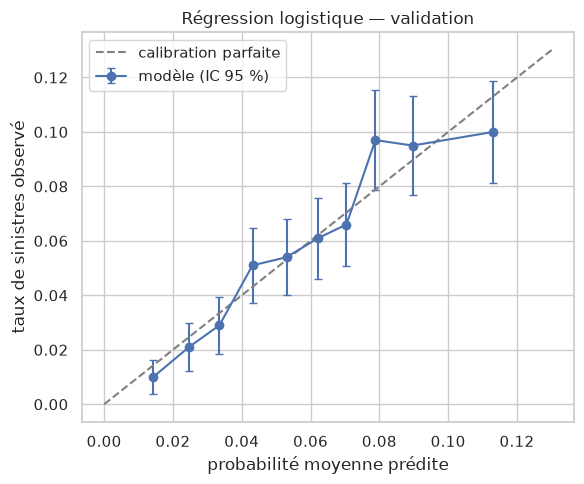

,prédit,observé,clients,IC 95 % (±),prédit dans l'IC
décile,,,,,
1,0.0142,0.010,1001,0.0062,True
2,0.0247,0.021,1000,0.0089,True
3,0.0335,0.029,1000,0.0104,True
4,0.0431,0.051,1000,0.0136,True
5,0.0530,0.054,1000,0.0140,True
6,0.0622,0.061,1000,0.0148,True
7,0.0704,0.066,1000,0.0154,True
8,0.0788,0.097,1000,0.0183,True
9,0.0897,0.095,1000,0.0182,True


In [34]:
proba_valid = reg_log.predict_proba(X_valid_prep)[:, 1]

# Tableau par décile de risque prédit
groupes_risque = pd.qcut(proba_valid, 10, labels=False) + 1
calibration = (pd.DataFrame({"prédit": proba_valid, "observé": y_valid.values})
               .groupby(groupes_risque).agg(prédit=("prédit", "mean"), observé=("observé", "mean"),
                                            clients=("observé", "size")))
calibration["IC 95 % (±)"] = 1.96 * np.sqrt(calibration["observé"] * (1 - calibration["observé"]) / calibration["clients"])
calibration["prédit dans l'IC"] = (calibration["prédit"] - calibration["observé"]).abs() <= calibration["IC 95 % (±)"]
calibration.index.name = "décile"

# Pente de calibration (sans régularisation)
logit = np.log(proba_valid / (1 - proba_valid)).reshape(-1, 1)
pente = LogisticRegression(C=1e6, max_iter=2000).fit(logit, y_valid).coef_[0][0]

print(f"Sinistres prédits = {proba_valid.sum():.0f} | sinistres observés = {y_valid.sum()}")
print(f"Pente de calibration = {pente:.2f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.errorbar(calibration["prédit"], calibration["observé"], yerr=calibration["IC 95 % (±)"],
            fmt="o-", capsize=3, label="modèle (IC 95 %)")
limite = calibration[["prédit", "observé"]].max().max() * 1.15
ax.plot([0, limite], [0, limite], "--", color="grey", label="calibration parfaite")
ax.set_title("Régression logistique — validation")
ax.set_xlabel("probabilité moyenne prédite")
ax.set_ylabel("taux de sinistres observé")
ax.legend()
plt.tight_layout()
plt.show()

calibration.round(4)

→ Le modèle est **bien calibré** : 583 sinistres prédits pour 584 observés, et une pente de calibration de 1,02.

Dans les 10 déciles, la probabilité prédite tombe dans l'intervalle de confiance à 95 % du taux observé. Les deux écarts les plus visibles restent dans cet intervalle :
- décile le plus risqué : 11,3 % prédit pour 10,0 % observé (intervalle ± 1,9 point) ;
- 8ᵉ décile : 7,9 % prédit pour 9,7 % observé (intervalle ± 1,8 point, juste à la limite).

Avec 1 000 clients par groupe, de tels écarts s'expliquent par le hasard de l'échantillon : on ne corrige pas la calibration.

### Interprétation de la régression logistique

Les variables étant standardisées (ou 0/1), on peut comparer les coefficients entre eux :
- un coefficient **positif** augmente le risque, un coefficient **négatif** le diminue ;
- pour une colonne 0/1, l'effet se lit **par rapport à la modalité de référence** (par exemple `type_contrat_Mini` par rapport à `Maxi`).

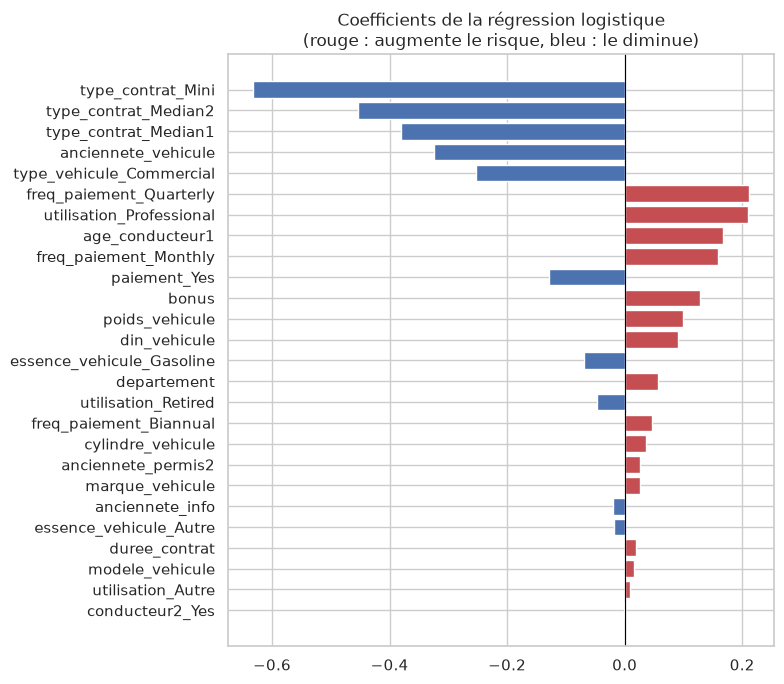

,coefficient
type_contrat_Mini,-0.632
type_contrat_Median2,-0.453
type_contrat_Median1,-0.380
anciennete_vehicule,-0.324
type_vehicule_Commercial,-0.253
freq_paiement_Quarterly,0.212
utilisation_Professional,0.210
age_conducteur1,0.168
freq_paiement_Monthly,0.159
paiement_Yes,-0.129


Coefficient de age_conducteur1 : 0.168
Âge moyen du conducteur principal selon l'usage (train) :
utilisation
AllTrips        51.0
Professional    51.4
Retired         72.1
WorkPrivate     48.0


In [35]:
coefficients = pd.Series(reg_log.coef_[0], index=X_train_prep.columns, name="coefficient")
coefficients = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index)

plt.figure(figsize=(8, 7))
couleurs = ["#C44E52" if c > 0 else "#4C72B0" for c in coefficients]
plt.barh(coefficients.index[::-1], coefficients.values[::-1], color=couleurs[::-1])
plt.axvline(0, color="black", lw=0.8)
plt.title("Coefficients de la régression logistique\n(rouge : augmente le risque, bleu : le diminue)")
plt.tight_layout()
plt.show()

display(coefficients.round(3).to_frame().head(10))

# age_conducteur1 : coefficient du modèle, et lien avec l'usage « Retired » (retraités)
print("Coefficient de age_conducteur1 :", round(coefficients["age_conducteur1"], 3))
print("Âge moyen du conducteur principal selon l'usage (train) :")
print(X_train.groupby("utilisation")["age_conducteur1"].mean().round(1).to_string())

**Prudence sur `age_conducteur1`.** Son coefficient est positif (+0,168 : à autres variables fixées, un conducteur plus âgé a un risque un peu plus élevé), alors que la variable seule n'a aucun signal (Gini univarié −0,047, §3.4).

C'est un effet **« toutes choses égales par ailleurs »** : il n'a de sens qu'en tenant compte des autres variables. Une explication probable est le lien avec l'usage : les conducteurs « Retired » ont 72,1 ans en moyenne, contre 48,0 ans pour « WorkPrivate ». Une partie de l'effet de l'âge est donc déjà portée par `utilisation`, et le coefficient de l'âge corrige ce qui reste.

Ce n'est qu'une hypothèse : on ne présente pas ce coefficient comme la preuve que « les conducteurs âgés sont plus risqués ».

### Conclusion de la partie 4 (avant les tests de variables)

**Gain par rapport à la référence**
- La régression logistique fait nettement mieux que le taux moyen : log-loss de validation **0,2138 contre 0,2225** (−3,9 %), et un **Gini de 0,313** contre 0 pour la référence.
- Le gain reste modeste en valeur absolue : la survenue d'un sinistre automobile est en grande partie **aléatoire**, et les variables disponibles n'en expliquent qu'une partie. C'est normal en tarification.

**Sous-apprentissage ou sur-apprentissage ?**
- Les scores sont quasiment identiques sur le train et la validation (log-loss 0,2135 / 0,2138, Gini 0,310 / 0,313) : **pas de sur-apprentissage**.
- La régularisation ne change rien (voir 4.3) : le levier n'est pas le réglage du modèle mais l'information apportée par les variables.

**Calibration** : 583 sinistres prédits pour 584 observés, pente de calibration 1,02, et les 10 déciles dans leur intervalle de confiance.

**Modèle retenu à ce stade : la régression logistique (C = 0,1).** Les sections suivantes testent si un meilleur traitement du véhicule ou un autre choix de variables fait mieux.

## 4.5 Le type de véhicule : marque et modèle

Le modèle de véhicule a un Gini univarié de 0,144, la marque de 0,033 (§3.4). Dans la préparation actuelle, chacun est remplacé par son **taux de sinistres lissé** vers le taux global ($m = 100$). On vérifie ici que la clé est propre, puis on compare plusieurs façons de traiter marque et modèle.

### Outil de comparaison (utilisé en 4.5 et 4.6)

Toutes les variantes sont évaluées **exactement de la même façon** :
- mêmes 5 plis de validation croisée que en 4.3 (`cv`, plis par client), sur le train seulement ;
- dans chaque pli, la préparation est apprise sur les 4 paquets d'entraînement, puis la régression logistique (C = 0,1) est évaluée sur le 5ᵉ ;
- on garde la log-loss, le Brier et le Gini **de chaque pli**.

**Comment décider si une variante est meilleure ?** On compare **pli par pli** : dans chaque pli, écart = log-loss de la variante − log-loss de la référence (négatif = la variante est meilleure). Comparer dans le même pli retire la « difficulté » propre à chaque pli, qui fait varier les scores d'environ ± 0,001. Ensuite :
- erreur-type de l'écart = écart-type des 5 écarts / $\sqrt{5}$ ;
- l'écart est **significatif** seulement si sa moyenne dépasse **deux erreurs-types** en valeur absolue. Sinon, le verdict est « égal ».

Ce test est volontairement simple. Avec 5 plis et beaucoup de variantes testées, une variante peut passer le seuil par hasard : un gain juste au-dessus du seuil doit être lu avec prudence.

In [36]:
from sklearn.metrics import log_loss

# Les 5 plis de 4.3, sous forme de positions (mêmes plis pour toutes les variantes)
positions_plis = list(cv.split(X_train, y_train, groups=groupes_train))


def scores_par_pli(preparer_pli, C=meilleur_C, **reglages):
    # Rejoue une variante sur les 5 plis. preparer_pli(X_entr, y_entr, X_eval, **reglages)
    # apprend la préparation sur X_entr et renvoie les deux tableaux préparés (A, B).
    lignes = []
    for pos_entr, pos_eval in positions_plis:
        X_entr, X_eval = X_train.iloc[pos_entr], X_train.iloc[pos_eval]
        y_entr, y_eval = y_train.iloc[pos_entr], y_train.iloc[pos_eval]
        A, B = preparer_pli(X_entr, y_entr, X_eval, **reglages)
        modele = LogisticRegression(C=C, max_iter=2000).fit(A, y_entr)
        lignes.append(evaluer(y_eval, modele.predict_proba(B)[:, 1]))
    return pd.DataFrame(lignes)  # une ligne par pli


def comparer(scores, reference):
    # Écart pli par pli sur la log-loss (négatif = la variante est meilleure) et verdict
    ecarts = scores["log-loss"] - reference["log-loss"]
    seuil = 2 * ecarts.std() / np.sqrt(len(ecarts))  # deux erreurs-types
    if abs(ecarts.mean()) <= seuil:
        verdict = "égal"
    else:
        verdict = "mieux" if ecarts.mean() < 0 else "pire"
    return {"log-loss CV": scores["log-loss"].mean(),
            "écart-type entre plis": scores["log-loss"].std(),
            "écart moyen vs référence": ecarts.mean(),
            "écart-type de l'écart": ecarts.std(),
            "seuil (2 erreurs-types)": seuil,
            "verdict": verdict,
            "Gini CV": scores["Gini"].mean(),
            "Brier CV": scores["Brier"].mean()}


def pli_actuel(X_entr, y_entr, X_eval, lissage=LISSAGE, redondantes=REDONDANTES):
    # Ma préparation actuelle (apprendre / preparer), apprise sur l'entraînement du pli
    p = apprendre(X_entr, y_entr, lissage, redondantes)
    return preparer(X_entr, p, y_entr), preparer(X_eval, p)


# Contrôle : la référence doit redonner la log-loss CV de 4.3
reference = scores_par_pli(pli_actuel)
print(f"Référence (préparation actuelle, C = {meilleur_C}) : log-loss CV = {reference['log-loss'].mean():.5f}")
print(f"Log-loss CV trouvée en 4.3 pour le même C : {recherche_reg_log.loc[meilleur_C, 'log-loss CV (moyenne)']:.5f}")
reference.round(5)

Référence (préparation actuelle, C = 0.1) : log-loss CV = 0.21427
Log-loss CV trouvée en 4.3 pour le même C : 0.21427


,log-loss,Brier,Gini
0,0.21503,0.05413,0.28525
1,0.21286,0.05399,0.32980
2,0.21337,0.05396,0.30871
3,0.21468,0.05416,0.29019
4,0.21540,0.05419,0.27251


### 1. Contrôle de la clé marque / modèle

On vérifie sur le train : le nombre de modèles et de couples (marque, modèle), les noms de modèle partagés par plusieurs marques, les variantes d'écriture (casse, espaces, tirets), les modèles rares, et les modèles du test ou de la validation absents du train.

In [37]:
modele, marque = X_train["modele_vehicule"], X_train["marque_vehicule"]
print("Modèles distincts (train)                :", modele.nunique())
print("Couples (marque, modèle) distincts       :", (marque + "|" + modele).nunique())

# Noms de modèle utilisés par plusieurs marques
marques_par_modele = X_train.groupby("modele_vehicule")["marque_vehicule"].nunique()
partages = marques_par_modele[marques_par_modele > 1].index
print("Noms de modèle présents chez plusieurs marques :", len(partages),
      f"({modele.isin(partages).sum()} lignes)")

# Variantes d'écriture : on compare le nombre de modalités avant / après normalisation
def normaliser(s):
    # majuscules, puis on ne garde que les lettres et les chiffres (espaces, tirets, points retirés)
    return s.str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
print("Modèles distincts après normalisation    :", normaliser(modele).nunique())
print("Marques distinctes / après normalisation :", marque.nunique(), "/", normaliser(marque).nunique())

# Modèles rares
lignes_par_modele = modele.value_counts()
for n in [20, 50, 100]:
    rares = lignes_par_modele[lignes_par_modele < n]
    print(f"Modèles de moins de {n:>3} lignes : {len(rares):>3} modèles, {rares.sum():>5} lignes ({rares.sum() / len(modele):.1%} du train)")

# Modèles absents du train
for nom, X in [("validation", X_valid), ("test Kaggle", X_test_kaggle)]:
    absents = ~X["modele_vehicule"].isin(lignes_par_modele.index)
    print(f"Lignes de la {nom} avec un modèle absent du train : {absents.sum()} ({absents.mean():.1%})")

display(X_train[modele.isin(partages)].groupby(["modele_vehicule", "marque_vehicule"]).size()
        .rename("lignes").to_frame().head(12))

Modèles distincts (train)                : 841
Couples (marque, modèle) distincts       : 878
Noms de modèle présents chez plusieurs marques : 35 (3184 lignes)
Modèles distincts après normalisation    : 841
Marques distinctes / après normalisation : 86 / 86
Modèles de moins de  20 lignes : 610 modèles,  2998 lignes (7.5% du train)
Modèles de moins de  50 lignes : 728 modèles,  6616 lignes (16.5% du train)
Modèles de moins de 100 lignes : 768 modèles,  9501 lignes (23.8% du train)
Lignes de la validation avec un modèle absent du train : 52 (0.5%)
Lignes de la test Kaggle avec un modèle absent du train : 258 (0.5%)


lignes
modele_vehicule marque_vehicule        
111             LADA VAZ              2
                ROVER                 7
1300            ALFA ROMEO            1
                BABOULIN              1
207             MERCEDES BENZ        13
                PEUGEOT             787
220             MERCEDES BENZ         1
                ROVER                 3
240             MERCEDES BENZ         6
                VOLVO                 8
307             MERCEDES BENZ         9
                PEUGEOT             995

,lignes,sinistres
count,841.0,841.0
mean,47.6,2.8
std,173.4,10.4
min,1.0,0.0
25%,2.0,0.0
50%,6.0,0.0
75%,22.0,1.0
90%,82.0,5.0
max,2914.0,154.0


Modèles avec 0 sinistre : 522 sur 841


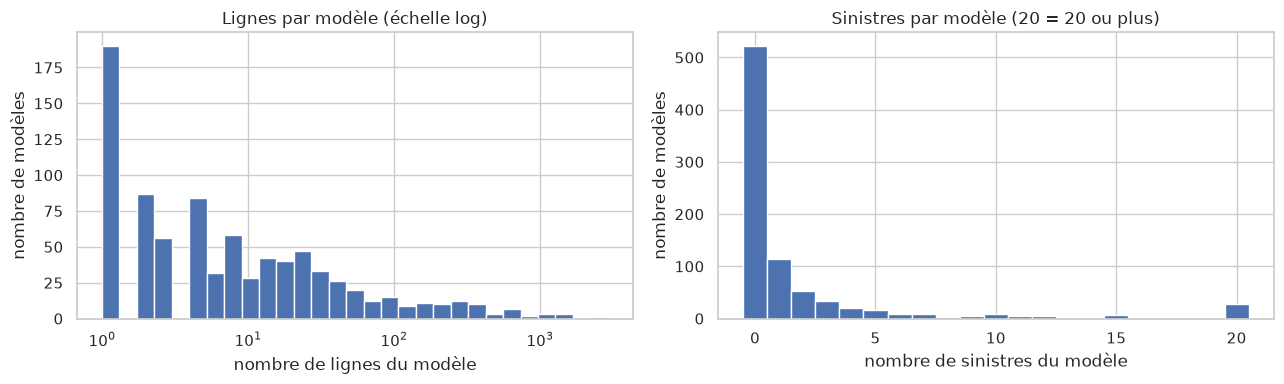

In [38]:
# Nombre de lignes et de sinistres par modèle (train)
par_modele = pd.DataFrame({"lignes": X_train.groupby("modele_vehicule").size(),
                           "sinistres": y_train.groupby(X_train["modele_vehicule"]).sum()})
display(par_modele.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))
print("Modèles avec 0 sinistre :", (par_modele["sinistres"] == 0).sum(), "sur", len(par_modele))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(par_modele["lignes"], bins=np.logspace(0, np.log10(par_modele["lignes"].max()), 30), color="#4C72B0")
axes[0].set_xscale("log")
axes[0].set_title("Lignes par modèle (échelle log)")
axes[0].set_xlabel("nombre de lignes du modèle")
axes[0].set_ylabel("nombre de modèles")
axes[1].hist(par_modele["sinistres"].clip(upper=20), bins=np.arange(22) - 0.5, color="#4C72B0")
axes[1].set_title("Sinistres par modèle (20 = 20 ou plus)")
axes[1].set_xlabel("nombre de sinistres du modèle")
axes[1].set_ylabel("nombre de modèles")
plt.tight_layout()
plt.show()

**Constats sur la clé**
- **841 modèles** distincts dans le train de 40 000 lignes (886 sur les 50 000 lignes, §2.3), et **878 couples** (marque, modèle).
- **35 noms de modèle** sont utilisés par plusieurs marques (3 184 lignes). Ce sont souvent des véhicules différents : « 207 » désigne 787 Peugeot et 13 Mercedes-Benz, « 307 » 995 Peugeot et 9 Mercedes-Benz. La clé « modèle seul » mélange donc quelques véhicules différents : la variante **d** teste la clé « marque|modèle ».
- **Aucune variante d'écriture** : mettre en majuscules et retirer espaces et tirets ne change rien (841 modèles et 86 marques avant comme après).
- **Beaucoup de modèles rares** : 610 modèles ont moins de 20 lignes (7,5 % des lignes du train), 728 moins de 50 (16,5 %), 768 moins de 100 (23,8 %).
- **Peu de modèles inconnus** : 52 lignes de la validation et 258 du test (0,5 % chacun) ont un modèle absent du train ; elles reçoivent le taux moyen.
- **Très peu de sinistres par modèle** : 2,8 en moyenne, et **0 pour la moitié des modèles** (médiane) ; 522 modèles sur 841 n'ont aucun sinistre. Un modèle a en moyenne 47,6 lignes, mais la moitié en ont 6 ou moins.

→ Pour la plupart des modèles, le taux de sinistres brut est du **bruit** (0 sinistre sur 6 lignes ne prouve rien). C'est pour cela que le taux est **lissé** vers le taux moyen.

### 2. Comparaison des traitements de marque et modèle

Variantes comparées à la version actuelle (**a**). Seule la colonne du véhicule change, tout le reste de la préparation est identique :

| Variante | Traitement |
|---|---|
| a | actuelle : taux du modèle lissé vers le taux global, $m = 100$ |
| b | même chose avec $m$ = 10, 20, 50, 300, 1000 (pour le modèle seulement) |
| c | **hiérarchique** : taux de la marque lissé vers le global, puis taux du couple (marque, modèle) lissé vers le taux **de sa marque** |
| d | clé unique « marque\|modèle » au lieu du modèle seul (lissée vers le global) |
| e | modèles de moins de N lignes (N = 20, 50, 100, comptées sur l'entraînement du pli) regroupés dans « Autre » |
| f | marque seule (colonne du modèle retirée) |
| g | ni marque ni modèle : seulement les caractéristiques techniques déjà présentes (puissance, poids, cylindrée, âge du véhicule…) |
| g' | ni marque ni modèle, en remettant `prix_vehicule` et `vitesse_vehicule` (retirées comme redondantes en 3.5) |

Chaque taux est appris **hors pli** sur l'entraînement du pli (paquets de clients), comme en 3.5.

In [39]:
def encoder_taux(cle_entr, y_entr, cle_eval, lissage=LISSAGE):
    # Taux lissé d'une clé : hors pli (par client) pour l'entraînement, appris sur tout l'entraînement
    # pour l'évaluation (clé inconnue -> taux moyen)
    valeurs_entr = taux_hors_pli(cle_entr.to_frame("cle"), y_entr, "cle", lissage)
    stats = y_entr.groupby(cle_entr).agg(["sum", "count"])
    taux = (stats["sum"] + lissage * y_entr.mean()) / (stats["count"] + lissage)
    return valeurs_entr, cle_eval.map(taux).fillna(y_entr.mean())


def remplacer_colonne(A, B, col, valeurs_A, valeurs_B):
    # Remplace une colonne par de nouvelles valeurs, standardisées avec la moyenne et l'écart-type de A
    A, B = A.copy(), B.copy()
    moyenne, ecart = valeurs_A.mean(), valeurs_A.std()
    A[col] = (valeurs_A - moyenne) / ecart
    B[col] = (valeurs_B - moyenne) / ecart
    return A, B


def cle_vehicule(X, cle, modeles_frequents=None):
    # Clé utilisée pour le taux du véhicule
    if cle == "couple":
        return X["marque_vehicule"] + "|" + X["modele_vehicule"]
    if modeles_frequents is not None:  # modèles rares regroupés dans "Autre"
        return X["modele_vehicule"].where(X["modele_vehicule"].isin(modeles_frequents), "Autre")
    return X["modele_vehicule"]


def pli_cle_modele(X_entr, y_entr, X_eval, cle="modele", lissage=LISSAGE, n_min=None):
    # Variantes a (contrôle), b, d, e : on recalcule seulement la colonne modele_vehicule
    A, B = pli_actuel(X_entr, y_entr, X_eval)
    frequents = None
    if n_min is not None:
        effectifs = X_entr["modele_vehicule"].value_counts()  # comptés sur l'entraînement du pli
        frequents = effectifs[effectifs >= n_min].index
    valeurs_A, valeurs_B = encoder_taux(cle_vehicule(X_entr, cle, frequents), y_entr,
                                        cle_vehicule(X_eval, cle, frequents), lissage)
    return remplacer_colonne(A, B, "modele_vehicule", valeurs_A, valeurs_B)

In [40]:
def taux_hierarchique(X_appr, y_appr, X_cible, lissage=LISSAGE):
    # 1. Taux de la marque, lissé vers le taux global
    taux_global = y_appr.mean()
    stats = y_appr.groupby(X_appr["marque_vehicule"]).agg(["sum", "count"])
    taux_marque = (stats["sum"] + lissage * taux_global) / (stats["count"] + lissage)
    # 2. Taux du couple (marque, modèle), lissé vers le taux DE SA MARQUE (et non vers le global)
    couple_appr = X_appr["marque_vehicule"] + "|" + X_appr["modele_vehicule"]
    couple_cible = X_cible["marque_vehicule"] + "|" + X_cible["modele_vehicule"]
    stats = y_appr.groupby(couple_appr).agg(["sum", "count"])
    a_priori = X_cible["marque_vehicule"].map(taux_marque).fillna(taux_global)  # marque inconnue -> global
    somme = couple_cible.map(stats["sum"]).fillna(0)
    nombre = couple_cible.map(stats["count"]).fillna(0)
    return (somme + lissage * a_priori) / (nombre + lissage)


def hierarchique_hors_pli(X, y, lissage=LISSAGE, nb_plis=5):
    # Même principe que taux_hors_pli : chaque paquet de clients reçoit le taux appris sur les 4 autres
    pli = plis_par_client(X, nb_plis)
    resultat = pd.Series(np.nan, index=X.index)
    for k in range(nb_plis):
        autres = pli != k
        resultat[~autres] = taux_hierarchique(X[autres], y[autres], X[~autres], lissage).values
    return resultat


def pli_hierarchique(X_entr, y_entr, X_eval, lissage=LISSAGE):
    # Variante c : la colonne modele_vehicule devient le taux hiérarchique marque -> modèle
    A, B = pli_actuel(X_entr, y_entr, X_eval)
    return remplacer_colonne(A, B, "modele_vehicule", hierarchique_hors_pli(X_entr, y_entr, lissage),
                             taux_hierarchique(X_entr, y_entr, X_eval, lissage))


def pli_sans(X_entr, y_entr, X_eval, colonnes=(), redondantes=REDONDANTES):
    # Variantes f, g, g' : on retire des colonnes (et on peut remettre des variables redondantes)
    A, B = pli_actuel(X_entr, y_entr, X_eval, redondantes=redondantes)
    return A.drop(columns=list(colonnes)), B.drop(columns=list(colonnes))

In [41]:
# Contrôle : recalculer la colonne du modèle avec les nouvelles fonctions doit redonner exactement la référence
controle = scores_par_pli(pli_cle_modele)
print("Contrôle identique à la référence :", np.allclose(controle["log-loss"], reference["log-loss"]))

sans_prix_vitesse = [c for c in REDONDANTES if c not in ("prix_vehicule", "vitesse_vehicule")]
variantes_vehicule = {
    "b. lissage 10": (pli_cle_modele, {"lissage": 10}),
    "b. lissage 20": (pli_cle_modele, {"lissage": 20}),
    "b. lissage 50": (pli_cle_modele, {"lissage": 50}),
    "b. lissage 300": (pli_cle_modele, {"lissage": 300}),
    "b. lissage 1000": (pli_cle_modele, {"lissage": 1000}),
    "c. hiérarchique marque -> modèle": (pli_hierarchique, {}),
    "d. clé marque|modèle": (pli_cle_modele, {"cle": "couple"}),
    "e. modèles < 20 lignes -> Autre": (pli_cle_modele, {"n_min": 20}),
    "e. modèles < 50 lignes -> Autre": (pli_cle_modele, {"n_min": 50}),
    "e. modèles < 100 lignes -> Autre": (pli_cle_modele, {"n_min": 100}),
    "f. marque seule": (pli_sans, {"colonnes": ["modele_vehicule"]}),
    "g. ni marque ni modèle": (pli_sans, {"colonnes": ["modele_vehicule", "marque_vehicule"]}),
    "g'. ni marque ni modèle, + prix et vitesse": (pli_sans, {"colonnes": ["modele_vehicule", "marque_vehicule"],
                                                             "redondantes": sans_prix_vitesse}),
}

scores_vehicule = {"a. actuelle (modèle, lissage 100)": reference}
for nom, (fonction, reglages) in variantes_vehicule.items():
    scores_vehicule[nom] = scores_par_pli(fonction, **reglages)

resultats_vehicule = pd.DataFrame({nom: comparer(s, reference) for nom, s in scores_vehicule.items()}).T
ecarts_par_pli = pd.DataFrame({nom: s["log-loss"] - reference["log-loss"] for nom, s in scores_vehicule.items()}).T
ecarts_par_pli.columns = [f"pli {k + 1}" for k in range(len(positions_plis))]

display(resultats_vehicule.round(5))
print("Écart de log-loss pli par pli avec la version actuelle (négatif = mieux) :")
display(ecarts_par_pli.round(5))

Contrôle identique à la référence : True


,log-loss CV,écart-type entre plis,écart moyen vs référence,écart-type de l'écart,seuil (2 erreurs-types),verdict,Gini CV,Brier CV
"a. actuelle (modèle, lissage 100)",0.214268,0.001098,0.0,0.0,0.0,égal,0.297293,0.054085
b. lissage 10,0.214285,0.001069,0.000018,0.000043,0.000038,égal,0.296699,0.054087
b. lissage 20,0.21429,0.001085,0.000022,0.000024,0.000021,pire,0.29671,0.054089
b. lissage 50,0.214276,0.001097,0.000009,0.000008,0.000007,pire,0.297007,0.054087
b. lissage 300,0.214265,0.001098,-0.000002,0.000009,0.000008,égal,0.297425,0.054085
b. lissage 1000,0.214266,0.001091,-0.000002,0.000012,0.000011,égal,0.297491,0.054085
c. hiérarchique marque -> modèle,0.214264,0.001083,-0.000004,0.000018,0.000016,égal,0.297377,0.054085
d. clé marque|modèle,0.214268,0.001098,0.0,0.000002,0.000002,égal,0.29728,0.054085
e. modèles < 20 lignes -> Autre,0.214279,0.001107,0.000011,0.000024,0.000022,égal,0.297075,0.054088
e. modèles < 50 lignes -> Autre,0.21428,0.0011,0.000012,0.000026,0.000023,égal,0.297146,0.054087


Écart de log-loss pli par pli avec la version actuelle (négatif = mieux) :


,pli 1,pli 2,pli 3,pli 4,pli 5
"a. actuelle (modèle, lissage 100)",0.00000,0.00000,0.00000,0.00000,0.00000
b. lissage 10,-0.00002,0.00002,0.00008,0.00002,-0.00002
b. lissage 20,0.00001,0.00002,0.00005,0.00004,-0.00000
b. lissage 50,0.00001,0.00001,0.00001,0.00002,-0.00000
b. lissage 300,0.00000,-0.00001,0.00001,-0.00002,0.00000
b. lissage 1000,0.00000,0.00001,0.00000,-0.00002,-0.00000
c. hiérarchique marque -> modèle,-0.00000,0.00001,0.00001,-0.00001,-0.00003
d. clé marque|modèle,-0.00000,0.00000,-0.00000,0.00000,0.00000
e. modèles < 20 lignes -> Autre,0.00001,0.00000,-0.00001,0.00005,0.00000
e. modèles < 50 lignes -> Autre,0.00005,0.00001,0.00002,-0.00002,-0.00000


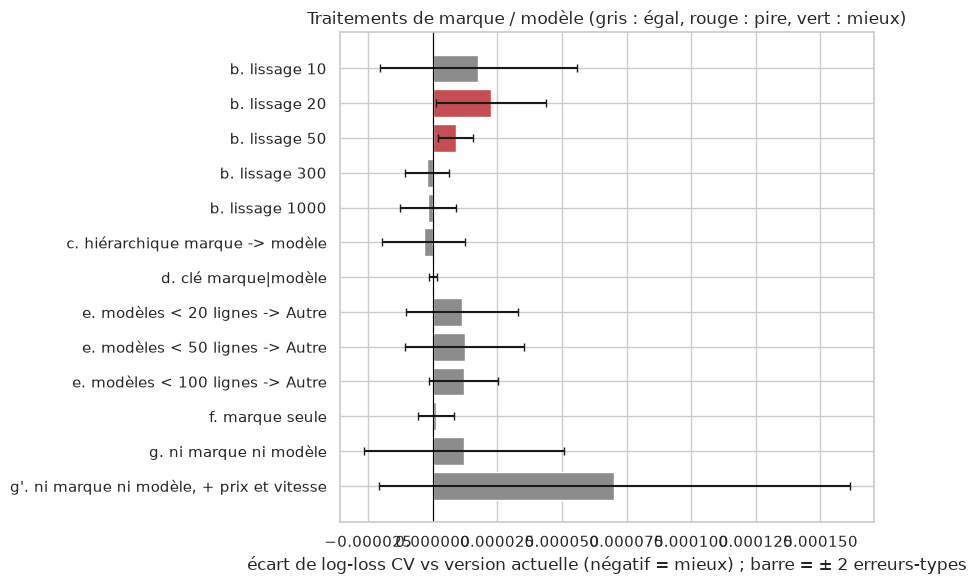

In [42]:
# Écart moyen de chaque variante, avec la marge de deux erreurs-types
r = resultats_vehicule.drop(index="a. actuelle (modèle, lissage 100)")
fig, ax = plt.subplots(figsize=(9, 6))
couleurs = ["#C44E52" if v == "pire" else "#55A868" if v == "mieux" else "#8C8C8C" for v in r["verdict"]]
ax.barh(r.index[::-1], r["écart moyen vs référence"][::-1], xerr=r["seuil (2 erreurs-types)"][::-1],
        color=couleurs[::-1], capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("écart de log-loss CV vs version actuelle (négatif = mieux) ; barre = ± 2 erreurs-types")
ax.set_title("Traitements de marque / modèle (gris : égal, rouge : pire, vert : mieux)")
plt.tight_layout()
plt.show()

**Résultats**

→ **Aucun traitement ne bat la version actuelle.** Tous les écarts moyens sont compris entre −0,000004 et +0,00007 : au moins 15 fois plus petits que l'écart-type entre plis (environ 0,0011).

- **Lissage (b)** : 300 et 1000 font jeu égal (−0,000002). Un lissage faible (10 à 50) est légèrement moins bon : il prend trop au sérieux les petits modèles. Pour 20 et 50, le test conclut même « pire », car les 5 écarts sont très réguliers. Mais ces écarts (+0,000022 et +0,000009) sont 50 à 100 fois plus petits que la variation entre plis : ils n'ont **aucune importance pratique**.
- **Taux hiérarchique (c)** : la meilleure moyenne (−0,000004), mais sous le seuil : « égal ».
- **Clé marque|modèle (d)** : strictement identique (écart 0,000000). Les 35 noms partagés pèsent trop peu pour changer quelque chose.
- **Regroupement des modèles rares (e)** : légèrement moins bon (+0,000011 à +0,000012), « égal ». Le lissage traite déjà les modèles rares.
- **Marque seule (f)** : « égal » (+0,000001).
- **Ni marque ni modèle (g)** : « égal » (+0,000012). **Une fois les caractéristiques techniques connues (âge, puissance, poids, cylindrée), marque et modèle n'apportent plus d'information mesurable.** Le Gini univarié du modèle (0,144) vient surtout de ce qu'il résume : un modèle de véhicule, c'est d'abord une puissance, un prix et un âge.
- **Remettre prix et vitesse à la place (g')** : « égal » (+0,00007), donc pas utile.

**Décision** : on garde la **version actuelle** (taux du modèle lissé vers le global, $m = 100$), car aucune variante ne gagne de façon significative. Retirer marque et modèle serait une simplification sans perte mesurable : elle est rediscutée en 4.6 avec les autres variables.

### 3. Contrôle de fuite sur la version retenue

On refait la vérification de 3.6 pour le traitement retenu : la colonne du véhicule, apprise sur le train (hors pli), doit avoir à peu près la même corrélation avec le sinistre sur le train et sur la validation.

In [43]:
# Version retenue : la meilleure variante « mieux » s'il y en a une, sinon la version actuelle
mieux = resultats_vehicule[resultats_vehicule["verdict"] == "mieux"]
nom_vehicule_retenu = (mieux["log-loss CV"].astype(float).idxmin() if len(mieux)
                       else "a. actuelle (modèle, lissage 100)")
fonction, reglages = variantes_vehicule.get(nom_vehicule_retenu, (pli_actuel, {}))
print("Traitement retenu :", nom_vehicule_retenu)

# Préparation apprise sur tout le train, appliquée à la validation
A, B = fonction(X_train, y_train, X_valid, **reglages)
colonnes_vehicule = [c for c in ["marque_vehicule", "modele_vehicule"] if c in A.columns]
pd.DataFrame({"corrélation train": A[colonnes_vehicule].corrwith(y_train),
              "corrélation validation": B[colonnes_vehicule].corrwith(y_valid)}).round(3)

Traitement retenu : a. actuelle (modèle, lissage 100)


,corrélation train,corrélation validation
marque_vehicule,0.023,0.016
modele_vehicule,0.063,0.059


→ **Pas de fuite** : pour la version retenue, la colonne du modèle a une corrélation de 0,063 sur le train contre 0,059 sur la validation, et la marque 0,023 contre 0,016. Les valeurs sont proches, comme en 3.6 : le calcul hors pli par client fonctionne.

## 4.6 Tests de variables et de combinaisons

Objectif : savoir quelles variables comptent vraiment, et si un modèle plus petit suffit.

**Référence** : le modèle actuel (préparation de 3.5, C = 0,1), qui utilise **19 variables** : les 25 variables conservées en 3.1, moins les 6 variables redondantes retirées en 3.5. Même outil qu'en 4.5 : mêmes 5 plis, log-loss comme critère principal, Gini et Brier en complément, test « deux erreurs-types » sur l'écart pli par pli.

**Familles de variables** (d'après les vraies colonnes) :

| Famille | Variables |
|---|---|
| Véhicule (12) | âge (`anciennete_vehicule`, `debut_vente_vehicule`, `fin_vente_vehicule`), puissance et gamme (`cylindre_vehicule`, `din_vehicule`, `vitesse_vehicule`, `prix_vehicule`, `poids_vehicule`), `essence_vehicule`, `type_vehicule`, `marque_vehicule`, `modele_vehicule` |
| Conducteur (5) | `age_conducteur1`, `anciennete_permis1`, `conducteur2`, `age_conducteur2`, `anciennete_permis2` |
| Contrat (7) | `type_contrat`, `bonus`, `duree_contrat`, `anciennete_info`, `freq_paiement`, `paiement`, `utilisation` |
| Géographie (1) | `departement` |

**Méthode** : dans chaque pli, on prépare une seule fois une version avec **toutes** les variables (aucune redondante retirée). Chaque test garde ensuite seulement les colonnes de ses variables. C'est équivalent à refaire la préparation, car chaque traitement (imputation, taux lissé, one-hot, standardisation) se fait variable par variable. Un contrôle le vérifie ci-dessous.

In [44]:
FAMILLES = {
    "véhicule": ["anciennete_vehicule", "debut_vente_vehicule", "fin_vente_vehicule", "cylindre_vehicule",
                 "din_vehicule", "vitesse_vehicule", "prix_vehicule", "poids_vehicule",
                 "essence_vehicule", "type_vehicule", "marque_vehicule", "modele_vehicule"],
    "conducteur": ["age_conducteur1", "anciennete_permis1", "conducteur2", "age_conducteur2", "anciennete_permis2"],
    "contrat": ["type_contrat", "bonus", "duree_contrat", "anciennete_info", "freq_paiement", "paiement",
                "utilisation"],
    "géographie": ["departement"],
}
TOUTES = [v for variables in FAMILLES.values() for v in variables]
assert sorted(TOUTES) == sorted(X_train.columns)        # les familles couvrent exactement mes colonnes
ACTUELLES = [v for v in TOUTES if v not in REDONDANTES]   # les 19 variables du modèle actuel
print("Variables du modèle actuel :", len(ACTUELLES), "sur", len(TOUTES))

# Préparation avec TOUTES les variables, une fois par pli (mêmes plis que partout)
plis_complets = []
for pos_entr, pos_eval in positions_plis:
    X_entr, X_eval = X_train.iloc[pos_entr], X_train.iloc[pos_eval]
    y_entr, y_eval = y_train.iloc[pos_entr], y_train.iloc[pos_eval]
    A, B = pli_actuel(X_entr, y_entr, X_eval, redondantes=[])
    plis_complets.append((X_entr, y_entr, A, X_eval, y_eval, B))


def colonnes_de(variables, colonnes):
    # Colonnes préparées d'une liste de variables : la colonne elle-même, ou ses colonnes one-hot « variable_modalité »
    return [c for c in colonnes if c in variables or any(c.startswith(v + "_") for v in variables)]


def scores_variables(variables, ajout=None, C=meilleur_C, **reglages):
    # Log-loss, Brier, Gini par pli pour une liste de variables.
    # ajout(A, B, X_entr, X_eval, **reglages) peut ajouter des colonnes construites à la main.
    lignes = []
    for X_entr, y_entr, A, X_eval, y_eval, B in plis_complets:
        A_v, B_v = A[colonnes_de(variables, A.columns)], B[colonnes_de(variables, B.columns)]
        if ajout is not None:
            A_v, B_v = ajout(A_v, B_v, X_entr, X_eval, **reglages)
        if A_v.shape[1] == 0:  # aucune variable : on prédit le taux moyen
            proba = np.full(len(y_eval), y_entr.mean())
        else:
            proba = LogisticRegression(C=C, max_iter=2000).fit(A_v, y_entr).predict_proba(B_v)[:, 1]
        lignes.append(evaluer(y_eval, proba))
    return pd.DataFrame(lignes)


ref_variables = scores_variables(ACTUELLES)
print("Contrôle : même résultat que la référence de 4.5 :", np.allclose(ref_variables["log-loss"], reference["log-loss"]))
print(f"Log-loss CV de la référence : {ref_variables['log-loss'].mean():.5f}")

Variables du modèle actuel : 19 sur 25


Contrôle : même résultat que la référence de 4.5 : True
Log-loss CV de la référence : 0.21427


### 1. Retrait d'une variable à la fois, puis d'une famille entière

On part du modèle actuel et on retire **une** variable (ou une famille entière). Si la log-loss augmente de façon significative (verdict « pire »), la variable apporte une information que les autres n'ont pas.

,variables,log-loss CV,écart moyen vs référence,seuil (2 erreurs-types),verdict,Gini CV
sans la famille véhicule,11,0.216328,0.00206,0.000646,pire,0.250719
sans la famille contrat,12,0.21539,0.001122,0.000217,pire,0.273683
sans type_contrat,18,0.214964,0.000696,0.000322,pire,0.281514
sans anciennete_vehicule,18,0.214813,0.000545,0.000371,pire,0.288074
sans bonus,18,0.2147,0.000432,0.000141,pire,0.289669
sans age_conducteur1,18,0.214558,0.000291,0.000076,pire,0.292032
sans la famille conducteur,16,0.214467,0.0002,0.000222,égal,0.294358
sans utilisation,18,0.214329,0.000061,0.000134,égal,0.296333
sans freq_paiement,18,0.214323,0.000055,0.000176,égal,0.296487
sans type_vehicule,18,0.214317,0.000049,0.000148,égal,0.295844


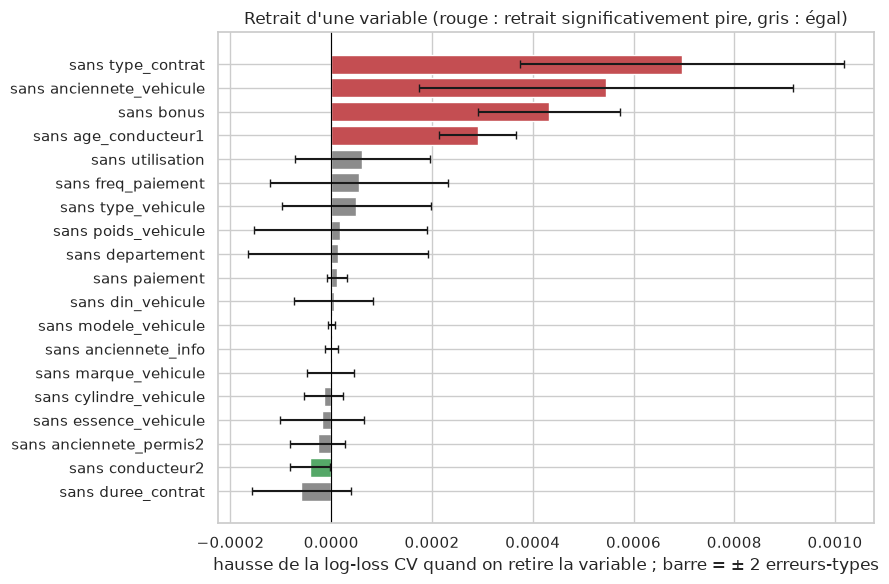

In [45]:
lignes = {}
for v in ACTUELLES:
    gardees = [x for x in ACTUELLES if x != v]
    lignes[f"sans {v}"] = {"variables": len(gardees), **comparer(scores_variables(gardees), ref_variables)}
for famille, membres in FAMILLES.items():
    gardees = [x for x in ACTUELLES if x not in membres]
    lignes[f"sans la famille {famille}"] = {"variables": len(gardees), **comparer(scores_variables(gardees), ref_variables)}

retraits = pd.DataFrame(lignes).T.sort_values("écart moyen vs référence", ascending=False)
colonnes_affichees = ["variables", "log-loss CV", "écart moyen vs référence", "seuil (2 erreurs-types)", "verdict", "Gini CV"]
display(retraits[colonnes_affichees])

# Graphique : ce que coûte le retrait de chaque variable (positif = la variable est utile)
r = retraits[~retraits.index.str.startswith("sans la famille")].sort_values("écart moyen vs référence")
fig, ax = plt.subplots(figsize=(9, 6))
couleurs = ["#C44E52" if v == "pire" else "#55A868" if v == "mieux" else "#8C8C8C" for v in r["verdict"]]
ax.barh(r.index, r["écart moyen vs référence"].astype(float), xerr=r["seuil (2 erreurs-types)"].astype(float),
        color=couleurs, capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("hausse de la log-loss CV quand on retire la variable ; barre = ± 2 erreurs-types")
ax.set_title("Retrait d'une variable (rouge : retrait significativement pire, gris : égal)")
plt.tight_layout()
plt.show()

**Résultats des retraits**

→ **Quatre variables sont indispensables** : les retirer dégrade la log-loss de façon significative.
- `type_contrat` : +0,00070 ;
- `anciennete_vehicule` : +0,00055 ;
- `bonus` : +0,00043 ;
- `age_conducteur1` : +0,00029.

Les deux dernières n'ont pourtant **aucun signal seules** (Gini univarié de 0,007 et −0,047, §3.4) : elles ne sont utiles qu'**en combinaison** avec les autres variables (effet « toutes choses égales par ailleurs »).

- **Familles** : retirer le véhicule (+0,00206) ou le contrat (+0,00112) est nettement pire. Retirer toute la famille conducteur (+0,00020) reste juste sous le seuil (0,00022). La géographie (département) n'apporte rien (+0,000013).
- **Les 15 autres variables** : leur retrait est « égal ». `conducteur2` sort même « mieux » (−0,000042 pour un seuil de 0,000040) : l'écart est minuscule et juste au seuil, on ne l'interprète pas.
- Attention : « égal » pour une variable retirée **seule** ne veut pas dire qu'on peut toutes les retirer **ensemble**, car elles peuvent se remplacer les unes les autres (voir les combinaisons plus bas).

### 2. Ajout progressif des variables

On part du **taux moyen** (aucune variable) et on ajoute les variables une par une, de la plus forte à la plus faible selon le Gini univarié.

L'ordre est calculé **en validation croisée sur le train** (Gini univarié moyen sur les 5 plis), et non sur la validation comme en 3.4. Ainsi, le jeu de validation ne sert pas à choisir les variables.

On cherche le **coude** : le plus petit nombre de variables à partir duquel le modèle n'est plus significativement moins bon que le modèle actuel.

In [46]:
# Ordre des variables : Gini univarié moyen sur les 5 plis (train seulement)
gini_cv = {}
for v in TOUTES:
    gini_cv[v] = np.mean([gini_univarie(X_entr[v], y_entr, X_eval[v], y_eval)
                          for X_entr, y_entr, _, X_eval, y_eval, _ in plis_complets])
ordre = pd.Series(gini_cv).sort_values(ascending=False)

etapes = []
for k in range(len(ordre) + 1):
    resultat = comparer(scores_variables(list(ordre.index[:k])), ref_variables)
    etapes.append({"nombre de variables": k, "variable ajoutée": ordre.index[k - 1] if k > 0 else "(taux moyen)",
                   "Gini univarié CV": ordre.iloc[k - 1] if k > 0 else np.nan, **resultat})
ajout_progressif = pd.DataFrame(etapes).set_index("nombre de variables")

# Coude : premier nombre de variables qui n'est plus « pire » que le modèle actuel
coude = ajout_progressif.index[ajout_progressif["verdict"] != "pire"][0]
print("Coude : à partir de", coude, "variables, le modèle n'est plus significativement moins bon que le modèle actuel")
display(ajout_progressif[["variable ajoutée", "Gini univarié CV", "log-loss CV", "écart moyen vs référence",
                          "seuil (2 erreurs-types)", "verdict", "Gini CV"]])

Coude : à partir de 19 variables, le modèle n'est plus significativement moins bon que le modèle actuel


,variable ajoutée,Gini univarié CV,log-loss CV,écart moyen vs référence,seuil (2 erreurs-types),verdict,Gini CV
nombre de variables,,,,,,,
0,(taux moyen),NaN,0.222338,0.008070,0.001005,pire,0.000000
1,anciennete_vehicule,0.245240,0.216688,0.002420,0.000685,pire,0.243163
2,debut_vente_vehicule,0.241651,0.216544,0.002277,0.000570,pire,0.247814
3,fin_vente_vehicule,0.241393,0.216517,0.002249,0.000544,pire,0.248662
4,type_contrat,0.197668,0.215733,0.001465,0.000239,pire,0.265064
5,din_vehicule,0.181685,0.214914,0.000646,0.000296,pire,0.287254
6,prix_vehicule,0.177463,0.214886,0.000618,0.000188,pire,0.288525
7,vitesse_vehicule,0.161309,0.214915,0.000647,0.000186,pire,0.287356
8,poids_vehicule,0.156471,0.214899,0.000631,0.000243,pire,0.288002


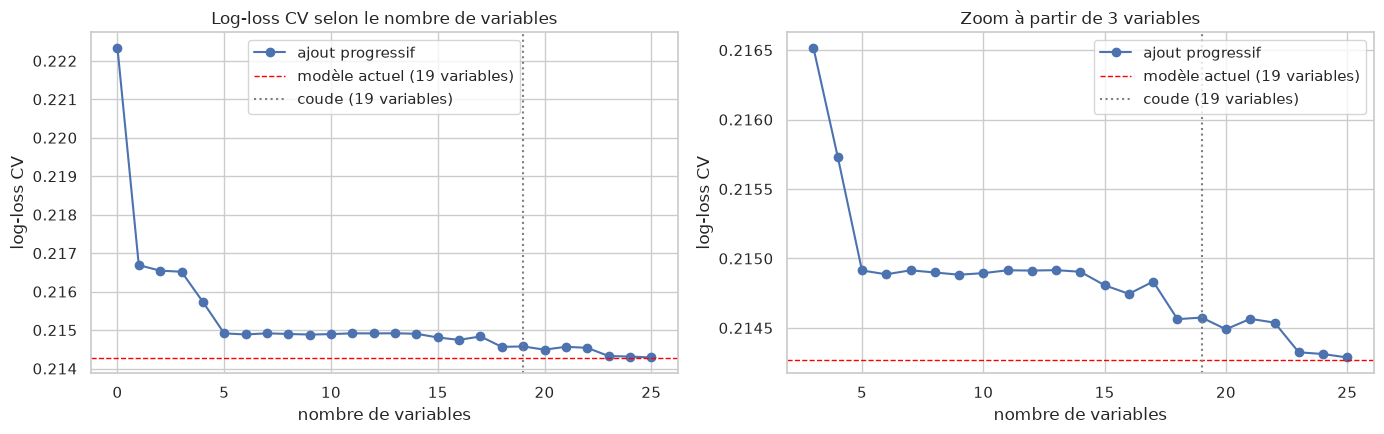

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
log_loss_k = ajout_progressif["log-loss CV"].astype(float)
for ax, debut in zip(axes, [0, 3]):
    partie = log_loss_k.loc[debut:]
    ax.plot(partie.index, partie.values, "o-", color="#4C72B0", label="ajout progressif")
    ax.axhline(ref_variables["log-loss"].mean(), color="red", ls="--", lw=1, label="modèle actuel (19 variables)")
    ax.axvline(coude, color="grey", ls=":", label=f"coude ({coude} variables)")
    ax.set_xlabel("nombre de variables")
    ax.set_ylabel("log-loss CV")
    ax.legend()
axes[0].set_title("Log-loss CV selon le nombre de variables")
axes[1].set_title("Zoom à partir de 3 variables")
plt.tight_layout()
plt.show()

**Résultats de l'ajout progressif**

→ **Trois variables font l'essentiel du gain** : l'âge du véhicule (log-loss de 0,22234 à 0,21669), le type de contrat (0,21573) et la puissance `din_vehicule` (0,21491). Ensuite, la courbe est presque plate, puis elle baisse encore avec `bonus` (18ᵉ variable, 0,21456) et `age_conducteur1` (23ᵉ, 0,21433).

- **Coude** : dans cet ordre, il faut **19 variables** pour ne plus être significativement moins bon que le modèle actuel.
- **L'ordre du Gini univarié est un mauvais guide.** `bonus` et `age_conducteur1`, faibles seuls, arrivent en fin de liste alors qu'ils sont utiles en combinaison. À l'inverse, les trois mesures redondantes de l'âge du véhicule passent en tête alors que seule la première apporte quelque chose (0,21669, puis 0,21654 et 0,21652). C'est pourquoi le modèle actuel, qui retire ces redondances, fait mieux avec le même nombre de variables.

### 3. Combinaisons de variables, variables métier, classes et interactions

| Test | Contenu |
|---|---|
| Minimal / moyen | les 6 / 12 premières variables de l'ordre ci-dessus, **sans les variables redondantes** (une seule mesure par groupe de 2.6) |
| Complet | les 25 variables, redondantes comprises |
| Actuel + prix / vitesse | remettre `prix_vehicule` et / ou `vitesse_vehicule` (ρ = 0,88 avec `din_vehicule`) |
| Variables métier | `jeune_conducteur2` (2ᵉ conducteur de moins de 26 ans), `malus` (bonus > 0,5), `puissance_poids` (puissance / poids) |
| 10 classes | chaque variable numérique remplacée par 10 classes de même effectif (bornes apprises sur l'entraînement du pli), en one-hot : le modèle peut alors suivre des effets non linéaires |
| Interactions | produits ajoutés à la main : âge du conducteur × puissance, âge du véhicule × puissance, âge du conducteur × âge du véhicule |
| Lissage | $m$ = 20 et 300 au lieu de 100, pour les trois taux (marque, modèle, département) |

In [48]:
def ajout_metier(A, B, X_entr, X_eval, quelles=("jeune_conducteur2", "malus", "puissance_poids")):
    # Variables métier construites à la main, à partir des données nettoyées
    A, B = A.copy(), B.copy()
    for T, X in [(A, X_entr), (B, X_eval)]:
        if "jeune_conducteur2" in quelles:
            T["jeune_conducteur2"] = ((X["conducteur2"] == "Yes") & (X["age_conducteur2"] < 26)).astype(int)
        if "malus" in quelles:
            T["malus"] = (X["bonus"] > 0.5).astype(int)
    if "puissance_poids" in quelles:
        ratio_A = X_entr["din_vehicule"] / X_entr["poids_vehicule"]
        ratio_B = X_eval["din_vehicule"] / X_eval["poids_vehicule"]
        mediane = ratio_A.median()  # poids manquant -> ratio médian de l'entraînement
        A, B = remplacer_colonne(A, B, "puissance_poids", ratio_A.fillna(mediane), ratio_B.fillna(mediane))
    return A, B


def ajout_interactions(A, B, X_entr, X_eval, paires=()):
    # Produit de deux colonnes standardisées, puis standardisé à son tour
    for v1, v2 in paires:
        A, B = remplacer_colonne(A, B, f"{v1} x {v2}", A[v1] * A[v2], B[v1] * B[v2])
    return A, B


def ajout_classes(A, B, X_entr, X_eval, numeriques=()):
    # Chaque variable numérique est remplacée par ses 10 classes (bornes apprises sur A), en one-hot
    for v in numeriques:
        c_A, c_B = classes_apprises(A[v], B[v])
        d_A = pd.get_dummies(c_A, prefix=f"{v}_classe", dtype=int)
        d_A = d_A.drop(columns=d_A.columns[0])  # la 1re classe sert de référence
        d_B = pd.get_dummies(c_B, prefix=f"{v}_classe", dtype=int).reindex(columns=d_A.columns, fill_value=0)
        A = pd.concat([A.drop(columns=v), d_A], axis=1)
        B = pd.concat([B.drop(columns=v), d_B], axis=1)
    return A, B


print("Jeunes 2es conducteurs (< 26 ans) dans le train :", ((X_train["conducteur2"] == "Yes") & (X_train["age_conducteur2"] < 26)).sum(),
      "| clients en malus (bonus > 0,5) :", (X_train["bonus"] > 0.5).sum())

ordre_sans_doublons = [v for v in ordre.index if v not in REDONDANTES]
NUMERIQUES_ACTUELLES = ["bonus", "duree_contrat", "anciennete_info", "age_conducteur1", "anciennete_permis2",
                        "anciennete_vehicule", "cylindre_vehicule", "din_vehicule", "poids_vehicule"]
sans_marque_modele = [v for v in ACTUELLES if v not in ("marque_vehicule", "modele_vehicule")]

combinaisons = {
    "minimal (6 variables)": (ordre_sans_doublons[:6], None, {}),
    "moyen (12 variables)": (ordre_sans_doublons[:12], None, {}),
    "complet (25 variables, redondantes gardées)": (TOUTES, None, {}),
    "actuel + prix": (ACTUELLES + ["prix_vehicule"], None, {}),
    "actuel + vitesse": (ACTUELLES + ["vitesse_vehicule"], None, {}),
    "actuel + prix + vitesse": (ACTUELLES + ["prix_vehicule", "vitesse_vehicule"], None, {}),
    "actuel sans marque ni modèle": (sans_marque_modele, None, {}),
    "actuel + 3 variables métier": (ACTUELLES, ajout_metier, {}),
    "actuel + jeune 2e conducteur": (ACTUELLES, ajout_metier, {"quelles": ["jeune_conducteur2"]}),
    "actuel + malus": (ACTUELLES, ajout_metier, {"quelles": ["malus"]}),
    "actuel + puissance / poids": (ACTUELLES, ajout_metier, {"quelles": ["puissance_poids"]}),
    "actuel, numériques en 10 classes": (ACTUELLES, ajout_classes, {"numeriques": NUMERIQUES_ACTUELLES}),
    "actuel + âge conducteur x puissance": (ACTUELLES, ajout_interactions, {"paires": [("age_conducteur1", "din_vehicule")]}),
    "actuel + âge véhicule x puissance": (ACTUELLES, ajout_interactions, {"paires": [("anciennete_vehicule", "din_vehicule")]}),
    "actuel + âge conducteur x âge véhicule": (ACTUELLES, ajout_interactions, {"paires": [("age_conducteur1", "anciennete_vehicule")]}),
}
nb_ajoutees = {"actuel + 3 variables métier": 3, "actuel + jeune 2e conducteur": 1, "actuel + malus": 1,
               "actuel + puissance / poids": 1, "actuel + âge conducteur x puissance": 1,
               "actuel + âge véhicule x puissance": 1, "actuel + âge conducteur x âge véhicule": 1}

lignes = {}
for nom, (variables, ajout, reglages) in combinaisons.items():
    lignes[nom] = {"variables": len(variables) + nb_ajoutees.get(nom, 0),
                   **comparer(scores_variables(variables, ajout, **reglages), ref_variables)}
for m in [20, 300]:  # le lissage change la préparation elle-même : on repasse par pli_actuel
    lignes[f"actuel, lissage {m}"] = {"variables": len(ACTUELLES),
                                      **comparer(scores_par_pli(pli_actuel, lissage=m), ref_variables)}

resultats_combinaisons = pd.DataFrame(lignes).T
print("Minimal :", ordre_sans_doublons[:6])
print("Moyen   :", ordre_sans_doublons[:12])
resultats_combinaisons[colonnes_affichees + ["Brier CV"]]

Jeunes 2es conducteurs (< 26 ans) dans le train : 1451 | clients en malus (bonus > 0,5) : 8890


Minimal : ['anciennete_vehicule', 'type_contrat', 'din_vehicule', 'poids_vehicule', 'modele_vehicule', 'cylindre_vehicule']
Moyen   : ['anciennete_vehicule', 'type_contrat', 'din_vehicule', 'poids_vehicule', 'modele_vehicule', 'cylindre_vehicule', 'essence_vehicule', 'marque_vehicule', 'anciennete_info', 'departement', 'utilisation', 'type_vehicule']


,variables,log-loss CV,écart moyen vs référence,seuil (2 erreurs-types),verdict,Gini CV,Brier CV
minimal (6 variables),6,0.214821,0.000553,0.00021,pire,0.288031,0.054164
moyen (12 variables),12,0.214699,0.000431,0.000211,pire,0.290408,0.054139
"complet (25 variables, redondantes gardées)",25,0.214287,0.00002,0.000285,égal,0.297073,0.0541
actuel + prix,20,0.214318,0.000051,0.000049,pire,0.296436,0.054094
actuel + vitesse,20,0.214291,0.000023,0.000035,égal,0.297038,0.054092
actuel + prix + vitesse,21,0.214347,0.00008,0.000086,égal,0.296271,0.0541
actuel sans marque ni modèle,17,0.21428,0.000012,0.000039,égal,0.297636,0.054092
actuel + 3 variables métier,22,0.213961,-0.000307,0.000159,mieux,0.302392,0.054039
actuel + jeune 2e conducteur,20,0.214091,-0.000176,0.000233,égal,0.301213,0.054059
actuel + malus,20,0.214255,-0.000012,0.000088,égal,0.297094,0.054081


**Résultats des combinaisons**

- **Un modèle plus petit ne suffit pas** : le minimal (6 variables, +0,00055) et le moyen (12 variables, +0,00043) sont pires. Il leur manque `bonus` et `age_conducteur1`.
- **Variables redondantes** : le complet à 25 variables fait jeu égal (+0,00002). Remettre `vitesse_vehicule` ou les deux ne change rien ; `prix_vehicule` seul sort « pire », mais de façon minuscule (+0,000051). Retirer les redondantes était donc le bon choix : plus simple, même performance.
- **Sans marque ni modèle** : égal (+0,000012), comme en 4.5.
- **Variables métier : le seul vrai gain.** Les trois ensemble gagnent −0,00031 (seuil 0,00016), soit **« mieux »**, et c'est le plus gros gain de toute la partie 4. Il vient surtout de `jeune_conducteur2` (−0,00018 seul, sous le seuil) et de `puissance_poids` (−0,00011, « mieux »). `malus` seul n'apporte rien (−0,000012) : l'information est déjà dans `bonus`.
- **Numériques en 10 classes** : pire (+0,00059). Le modèle a beaucoup plus de coefficients et sur-apprend ; les effets sont assez réguliers pour une simple pente.
- **Interactions ajoutées à la main** : égal (de +0,000008 à +0,000039).
- **Lissage** : $m = 300$ fait un peu mieux (−0,000029, seuil 0,000016) et $m = 20$ un peu moins bien (+0,000043), mais ces écarts sont 25 à 40 fois plus petits que la variation entre plis (environ 0,0011) : aucune importance pratique.

### 4. Tableau récapitulatif

Une ligne par modèle testé en 4.5 et 4.6 (les principaux), comparé au modèle actuel. Verdict : « mieux » / « pire » seulement si l'écart moyen dépasse deux erreurs-types, sinon « égal ».

In [49]:
recap = pd.concat([
    pd.DataFrame({"modèle actuel (référence)": {"variables": len(ACTUELLES), **comparer(ref_variables, ref_variables)}}).T,
    ajout_progressif.loc[[0, coude]].assign(variables=lambda d: d.index)
        .rename(index={0: "taux moyen (aucune variable)", coude: f"ajout progressif : {coude} premières variables"}),
    resultats_combinaisons,
    retraits.loc[[f"sans la famille {f}" for f in FAMILLES]],
    resultats_vehicule.loc[["c. hiérarchique marque -> modèle", "d. clé marque|modèle"]].assign(variables=len(ACTUELLES)),
])
recap = recap[["variables", "log-loss CV", "écart moyen vs référence", "verdict", "Gini CV", "Brier CV"]]
recap["log-loss CV"] = recap["log-loss CV"].astype(float).round(5)
recap["écart moyen vs référence"] = recap["écart moyen vs référence"].astype(float).round(5)
recap["Gini CV"] = recap["Gini CV"].astype(float).round(4)
recap["Brier CV"] = recap["Brier CV"].astype(float).round(5)
recap

,variables,log-loss CV,écart moyen vs référence,verdict,Gini CV,Brier CV
modèle actuel (référence),19,0.21427,0.00000,égal,0.2973,0.05409
taux moyen (aucune variable),0,0.22234,0.00807,pire,0.0000,0.05492
ajout progressif : 19 premières variables,19,0.21457,0.00031,égal,0.2933,0.05413
minimal (6 variables),6,0.21482,0.00055,pire,0.2880,0.05416
moyen (12 variables),12,0.21470,0.00043,pire,0.2904,0.05414
"complet (25 variables, redondantes gardées)",25,0.21429,0.00002,égal,0.2971,0.05410
actuel + prix,20,0.21432,0.00005,pire,0.2964,0.05409
actuel + vitesse,20,0.21429,0.00002,égal,0.2970,0.05409
actuel + prix + vitesse,21,0.21435,0.00008,égal,0.2963,0.05410
actuel sans marque ni modèle,17,0.21428,0.00001,égal,0.2976,0.05409


### Conclusions des tests de variables

1. **Les 19 variables actuelles sont un bon compromis** : un modèle plus petit est pire (6 ou 12 variables), et ajouter les variables redondantes ne change rien.
2. **Le signal vient du véhicule et du contrat** : retirer la famille véhicule coûte +0,0021 de log-loss, la famille contrat +0,0011. Les variables clés sont l'âge du véhicule, sa puissance, le type de contrat et le bonus.
3. **Département, marque et modèle n'apportent rien de mesurable** une fois les autres variables connues.
4. **Les variables conducteur sont faibles**, mais `age_conducteur1` est utile en combinaison, et le seul ajout significatif vient de **variables métier construites à la main** : un jeune 2ᵉ conducteur et le rapport puissance / poids (−0,00031 pour les trois variables métier ensemble).
5. **Découper les variables en classes ou ajouter des interactions simples n'aide pas** la régression logistique.
6. **Prudence** : une soixantaine de comparaisons ont été faites en 4.5 et 4.6 ; quelques verdicts « mieux » ou « pire » juste au seuil peuvent être dus au hasard. Le gain des variables métier (deux fois le seuil) est le seul assez net pour être retenu.
7. **Prochaine étape** : le modèle final de ce notebook n'est pas encore modifié. Il faudra intégrer les variables métier, puis juger le résultat sur la **RMSE de la prime** (notebook 03, métrique Kaggle), face à la meilleure fréquence actuelle (logistique + courbes).

## 4.7 Probabilités hors pli, pour juger la fréquence sur la prime

Kaggle ne juge pas la log-loss mais la **RMSE de la prime** (probabilité × montant). Pour juger notre fréquence sur ce critère, le notebook 03 a besoin d'une probabilité pour **chacun des 50 000 contrats**, prédite par un modèle qui ne l'a **pas vu** pendant l'apprentissage.

On réutilise le découpage de 3.2 (`decoupage` : 5 plis par client, stratifiés) sur toutes les données d'entraînement. Le pli 1 est exactement notre jeu de validation. Pour chaque pli :
1. la préparation (`apprendre`) et la régression logistique (C = 0,1) sont apprises sur les 4 autres plis ;
2. on prédit la probabilité des contrats du pli.

Ce sont les **mêmes plis** que ceux des prédictions du binôme (`binome_composantes_oof_train.csv`), ce qu'on vérifie. Les deux fréquences sont donc comparables contrat par contrat.

In [50]:
# Probabilités hors pli sur les 50 000 contrats, avec les 5 plis du découpage de 3.2
proba_oof = pd.Series(np.nan, index=X_complet.index)
pli_oof = pd.Series(0, index=X_complet.index)
for k, (pos_appr, pos_eval) in enumerate(decoupage.split(X_complet, y_complet, groups=groupes), 1):
    X_appr, y_appr, X_eval = X_complet.iloc[pos_appr], y_complet.iloc[pos_appr], X_complet.iloc[pos_eval]
    p = apprendre(X_appr, y_appr)  # préparation apprise sur les 4 autres plis
    modele = LogisticRegression(C=meilleur_C, max_iter=2000).fit(preparer(X_appr, p, y_appr), y_appr)
    proba_oof.iloc[pos_eval] = modele.predict_proba(preparer(X_eval, p))[:, 1]
    pli_oof.iloc[pos_eval] = k

# Vérification : mêmes plis que les prédictions du binôme, et pli 1 = notre validation
binome_oof = pd.read_csv(RACINE / "Data" / "predictions" / "binome_composantes_oof_train.csv")
assert (binome_oof["index"].values == train["index"].values).all()
print("Mêmes plis que le binôme :", (binome_oof["pli"].values == pli_oof.values).all())
print("Pli 1 = jeu de validation :", set(X_complet.index[pli_oof == 1]) == set(X_valid.index))

# Comparaison avec la logistique de référence du binôme (ma version d'avant l'audit), sur les mêmes contrats
comparaison_oof = pd.DataFrame({
    "ma logistique (ce notebook)": evaluer(y_complet, proba_oof),
    "logistique de référence (binôme)": evaluer(y_complet, binome_oof["proba_logistique_reference"]),
    "logistique + courbes (binôme)": evaluer(y_complet, binome_oof["proba_logistique_courbes"]),
}).T
display(comparaison_oof.round(5))

# Fichier pour le notebook 03
export_oof = pd.DataFrame({"index": train["index"], "pli": pli_oof.values, "proba_pred": proba_oof.values})
export_oof.to_csv(RACINE / "Data" / "predictions" / "frequence_logistique_oof_train.csv", index=False)
print("Probabilités hors pli exportées :", len(export_oof), "contrats")

Mêmes plis que le binôme : True
Pli 1 = jeu de validation : True


,log-loss,Brier,Gini
ma logistique (ce notebook),0.21402,0.05409,0.30373
logistique de référence (binôme),0.21399,0.05408,0.30410
logistique + courbes (binôme),0.21386,0.05406,0.30617


Probabilités hors pli exportées : 50000 contrats


→ Les plis sont identiques à ceux du binôme, et le pli 1 est bien notre jeu de validation.

Sur les 50 000 contrats hors pli :
- **ma logistique actuelle** : log-loss 0,21402, Gini 0,304 ;
- **la logistique de référence du binôme**, qui est ma version d'avant l'audit : log-loss 0,21399, Gini 0,304 ;
- **la logistique + courbes du binôme** : log-loss 0,21386, Gini 0,306. C'est la meilleure des trois.

Les corrections de l'audit (bonus sans logarithme, taux hors pli tirés par client) rendent le modèle plus propre, mais ne l'améliorent pas en log-loss. Le notebook 03 compare ces fréquences sur la prime.

## Export des probabilités sur le test

Pour les prédictions finales, on **réentraîne** la régression logistique avec ses meilleurs réglages sur **toutes** les données d'entraînement (`X_complet` = train + validation) : la préparation est réapprise sur ces 50 000 lignes, puis appliquée au test Kaggle.

Le fichier `Data/predictions/frequence_logistique_test.csv` (colonnes `id` = `test["index"]` et `proba_pred`) peut ensuite être combiné avec une gravité dans le notebook 03.

In [51]:
# 1. Préparation réapprise sur toutes les données d'entraînement
params_final = apprendre(X_complet, y_complet)
X_complet_prep = preparer(X_complet, params_final, y_complet)
X_test_prep_final = preparer(X_test_kaggle, params_final)

# 2. Modèle final : mêmes réglages, entraîné sur les 50 000 lignes
modele_final = LogisticRegression(C=meilleur_C, max_iter=2000)
modele_final.fit(X_complet_prep, y_complet)
proba_test = modele_final.predict_proba(X_test_prep_final)[:, 1]

# 3. Fichier de probabilités pour le notebook 03 : colonnes id et proba_pred
export = pd.DataFrame({"id": test["index"], "proba_pred": proba_test})
assert export["id"].is_unique and len(export) == len(test)
assert export["proba_pred"].between(0, 1).all()
dossier_export = RACINE / "Data" / "predictions"
dossier_export.mkdir(parents=True, exist_ok=True)
export.to_csv(dossier_export / "frequence_logistique_test.csv", index=False)

print("Lignes exportées :", len(export))
print(f"Probabilité moyenne sur le test : {proba_test.mean():.4f} | taux de sinistres du train complet : {y_complet.mean():.4f}")
export.head()

Lignes exportées : 50000
Probabilité moyenne sur le test : 0.0581 | taux de sinistres du train complet : 0.0583


,id,proba_pred
0,50000,0.037184
1,50001,0.030251
2,50002,0.099163
3,50003,0.066645
4,50004,0.022216
